## Taller 2: 
#### Estudiante: Andres Camilo Beltrán 
#### Correo: ac.beltranc1@uniandes.edu.co

In [175]:
import pandas as pd
df = pd.read_csv("https://datascience-uniandes.github.io/PracticasMachineLearning/datos/churn.csv")

## 1. Entendimiento y preparación de los datos

In [176]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [177]:
# Estructura del dataset
print('Dimensiones (filas, columnas):', df.shape)
print()
df.info()
display(df.head())
display(df.describe().T)

# Separación de variables por tipo
continuas = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']
categoricas = ['country', 'gender', 'products_number']
binarias = ['credit_card', 'active_member']
objetivo = 'churn'

Dimensiones (filas, columnas): (10045, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  object 
 2   gender            10045 non-null  object 
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 863.4+ KB


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.690148,97.087963,95.0,584.000,652.00,718.000,1200.00
age,9745.0,38.937609,10.734222,-1.0,32.000,37.00,44.000,210.00
tenure,10045.0,5.018915,2.901585,-2.0,3.000,5.00,8.000,25.00
balance,9845.0,76317.500287,62422.434819,0.0,0.000,97042.60,127559.970,250898.09
products_number,10045.0,1.530114,0.581829,1.0,1.000,1.00,2.000,4.00
credit_card,10045.0,0.704530,0.456277,0.0,0.000,1.00,1.000,1.00
active_member,10045.0,0.514684,0.499809,0.0,0.000,1.00,1.000,1.00
estimated_salary,9695.0,100069.014751,57510.689111,-5000.0,51013.655,100130.95,149382.875,199992.48
churn,10045.0,0.203584,0.402683,0.0,0.000,0.00,0.000,1.00


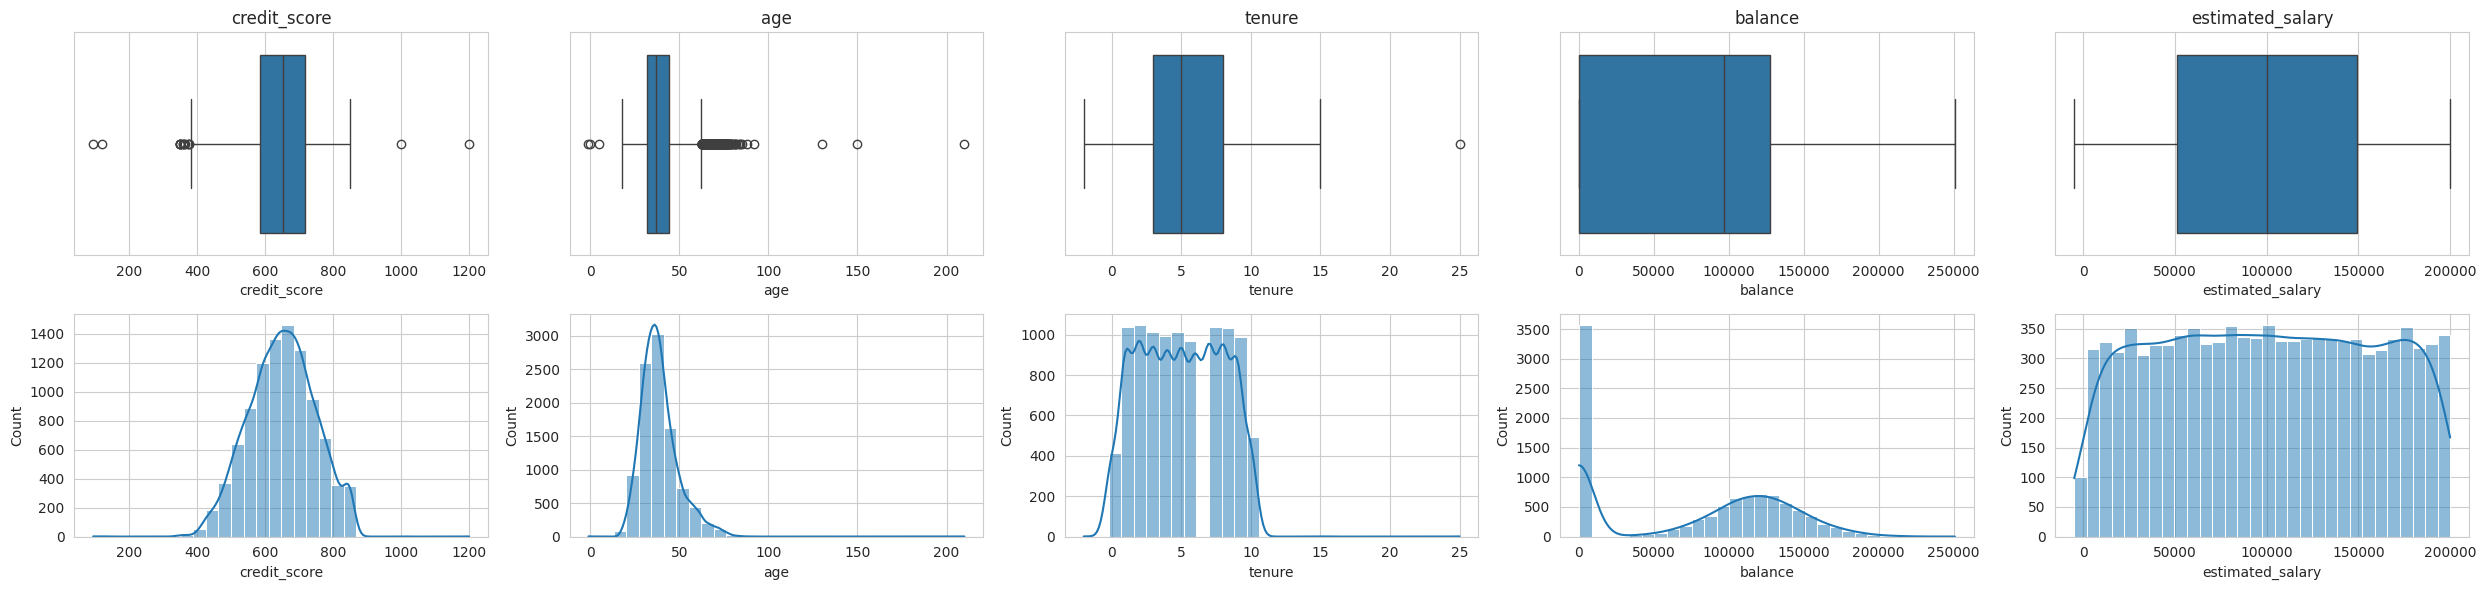

In [178]:
# Variables continuas: cajas e histogramas (datos originales)
fig, axes = plt.subplots(2, len(continuas), figsize=(5 * len(continuas), 6))
for i, columna in enumerate(continuas):
    sns.boxplot(x=df[columna], ax=axes[0, i])
    axes[0, i].set_title(columna)
    sns.histplot(df[columna], bins=30, kde=True, ax=axes[1, i])
plt.tight_layout()
plt.show()

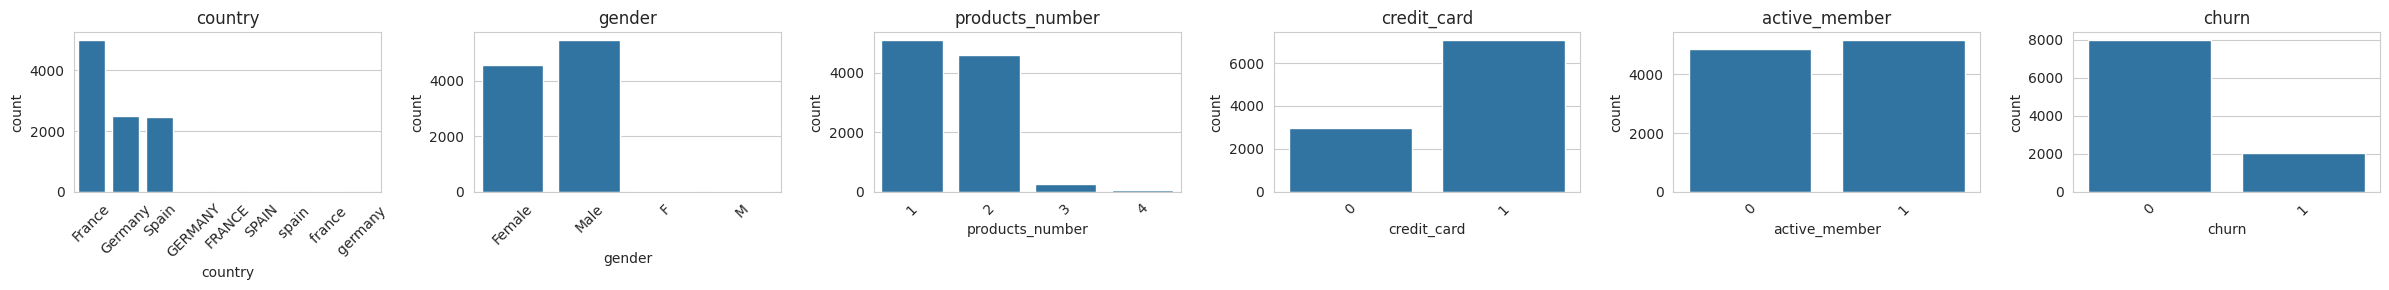

churn
0    0.796
1    0.204
Name: proportion, dtype: float64


In [179]:
# Variables categóricas, binarias y objetivo: gráficos de barras
columnas = categoricas + binarias + [objetivo]
fig, axes = plt.subplots(1, len(columnas), figsize=(4 * len(columnas), 3))
for ax, columna in zip(axes, columnas):
    sns.countplot(x=columna, data=df, ax=ax)
    ax.set_title(columna)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Proporción de cada clase del objetivo
print(df[objetivo].value_counts(normalize=True).round(3))

In [180]:
# Calidad de datos en cuatro dimensiones
# 1. Unicidad
print('Filas duplicadas:', df.duplicated().sum())

# 2. Completitud
print('\nPorcentaje de nulos por columna:')
print((df.isna().mean() * 100).round(2))

# 3. Consistencia
print('\nCategorías de country:\n', df['country'].value_counts())
print('\nCategorías de gender:\n', df['gender'].value_counts())

# 4. Validez (rangos según el diccionario de datos)
print('\nValores fuera de rango:')
print('credit_score fuera de [300, 850]:', (~df['credit_score'].dropna().between(300, 850)).sum())
print('age fuera de [18, 100]:', (~df['age'].dropna().between(18, 100)).sum())
print('tenure fuera de [0, 10]:', (~df['tenure'].between(0, 10)).sum())
print('estimated_salary < 0:', (df['estimated_salary'] < 0).sum())

Filas duplicadas: 45

Porcentaje de nulos por columna:
credit_score        2.49
country             0.00
gender              0.00
age                 2.99
tenure              0.00
balance             1.99
products_number     0.00
credit_card         0.00
active_member       0.00
estimated_salary    3.48
churn               0.00
dtype: float64

Categorías de country:
 country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64

Categorías de gender:
 gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64

Valores fuera de rango:
credit_score fuera de [300, 850]: 4
age fuera de [18, 100]: 6
tenure fuera de [0, 10]: 3
estimated_salary < 0: 3


In [181]:
df_clean = df.copy()

# 1. Eliminar duplicados
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 2. Unificar escritura de categorías
df_clean['country'] = df_clean['country'].str.strip().str.lower()
df_clean['country'] = df_clean['country'].replace({'france': 'France', 'germany': 'Germany', 'spain': 'Spain'})
df_clean['gender'] = df_clean['gender'].str.strip().str.lower()
df_clean['gender'] = df_clean['gender'].replace({'m': 'Male', 'male': 'Male', 'f': 'Female', 'female': 'Female'})

# 3. Valores inválidos: se llevan al límite válido más cercano
df_clean['age'] = df_clean['age'].clip(lower=18, upper=100)
df_clean['credit_score'] = df_clean['credit_score'].clip(lower=300, upper=850)
df_clean['tenure'] = df_clean['tenure'].clip(lower=0, upper=10)
df_clean['estimated_salary'] = df_clean['estimated_salary'].clip(lower=0)

print('Dimensiones después de la limpieza:', df_clean.shape)
print(df_clean['country'].value_counts(), df_clean['gender'].value_counts(), sep='\n\n')
display(df_clean.describe().loc[['min', 'max']].T)

Dimensiones después de la limpieza: (10000, 11)
country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

gender
Male      5457
Female    4543
Name: count, dtype: int64


,min,max
credit_score,300.0,850.00
age,18.0,100.00
tenure,0.0,10.00
balance,0.0,250898.09
products_number,1.0,4.00
credit_card,0.0,1.00
active_member,0.0,1.00
estimated_salary,0.0,199992.48
churn,0.0,1.00


credit_score: 14 atípicos
age: 347 atípicos
tenure: 0 atípicos
balance: 0 atípicos
estimated_salary: 0 atípicos
age: límites [21.0, 72.0]
credit_score: límites [432.0, 850.0]


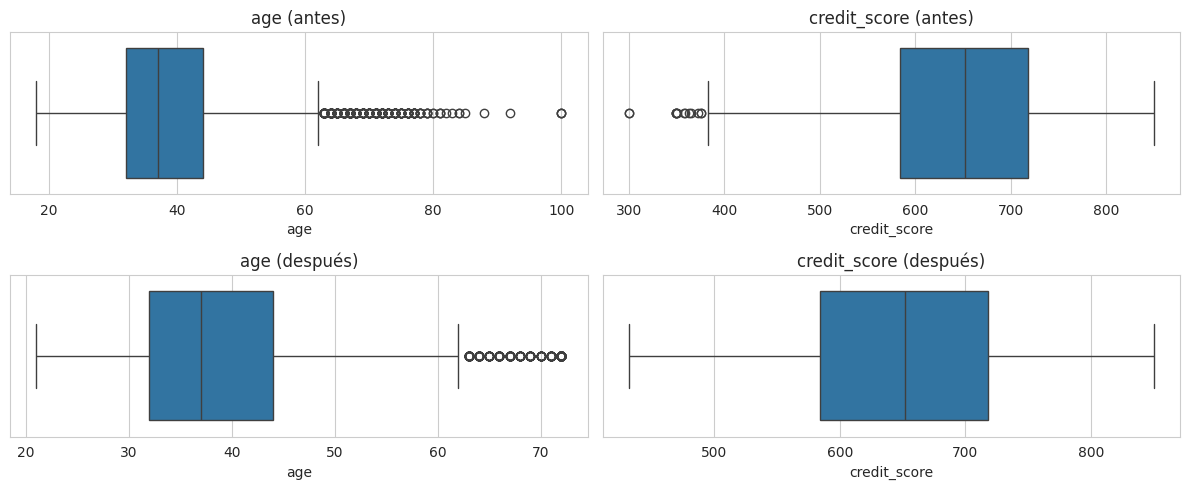

,count,mean,std,min,25%,50%,75%,max
age,9700.0,38.930103,10.530092,18.0,32.0,37.0,44.0,100.0
credit_score,9750.0,650.593026,96.768001,300.0,584.0,652.0,718.0,850.0


,count,mean,std,min,25%,50%,75%,max
age,9700.0,38.901443,10.329442,21.0,32.0,37.0,44.0,72.0
credit_score,9750.0,650.817231,96.195754,432.0,584.0,652.0,718.0,850.0


In [182]:
# Valores atípicos: conteo con la regla del rango intercuartílico (IQR)
for columna in continuas:
    q1, q3 = df_clean[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_atipicos = ((df_clean[columna] < inferior) | (df_clean[columna] > superior)).sum()
    print(f'{columna}: {n_atipicos} atípicos')

# Se recortan con percentiles 1 y 99 las variables que tienen atípicos (age y credit_score)
atipicas = ['age', 'credit_score']
df_antes = df_clean[atipicas].copy()
for columna in atipicas:
    inferior, superior = df_clean[columna].quantile([0.01, 0.99])
    print(f'{columna}: límites [{inferior:.1f}, {superior:.1f}]')
    df_clean[columna] = df_clean[columna].clip(lower=inferior, upper=superior)

# Comparación antes y después
fig, axes = plt.subplots(2, len(atipicas), figsize=(6 * len(atipicas), 5))
for i, columna in enumerate(atipicas):
    sns.boxplot(x=df_antes[columna], ax=axes[0, i])
    axes[0, i].set_title(f'{columna} (antes)')
    sns.boxplot(x=df_clean[columna], ax=axes[1, i])
    axes[1, i].set_title(f'{columna} (después)')
plt.tight_layout()
plt.show()
display(df_antes.describe().T)
display(df_clean[atipicas].describe().T)

credit_score        2.5
country             0.0
gender              0.0
age                 3.0
tenure              0.0
balance             2.0
products_number     0.0
credit_card         0.0
active_member       0.0
estimated_salary    3.5
churn               0.0
dtype: float64


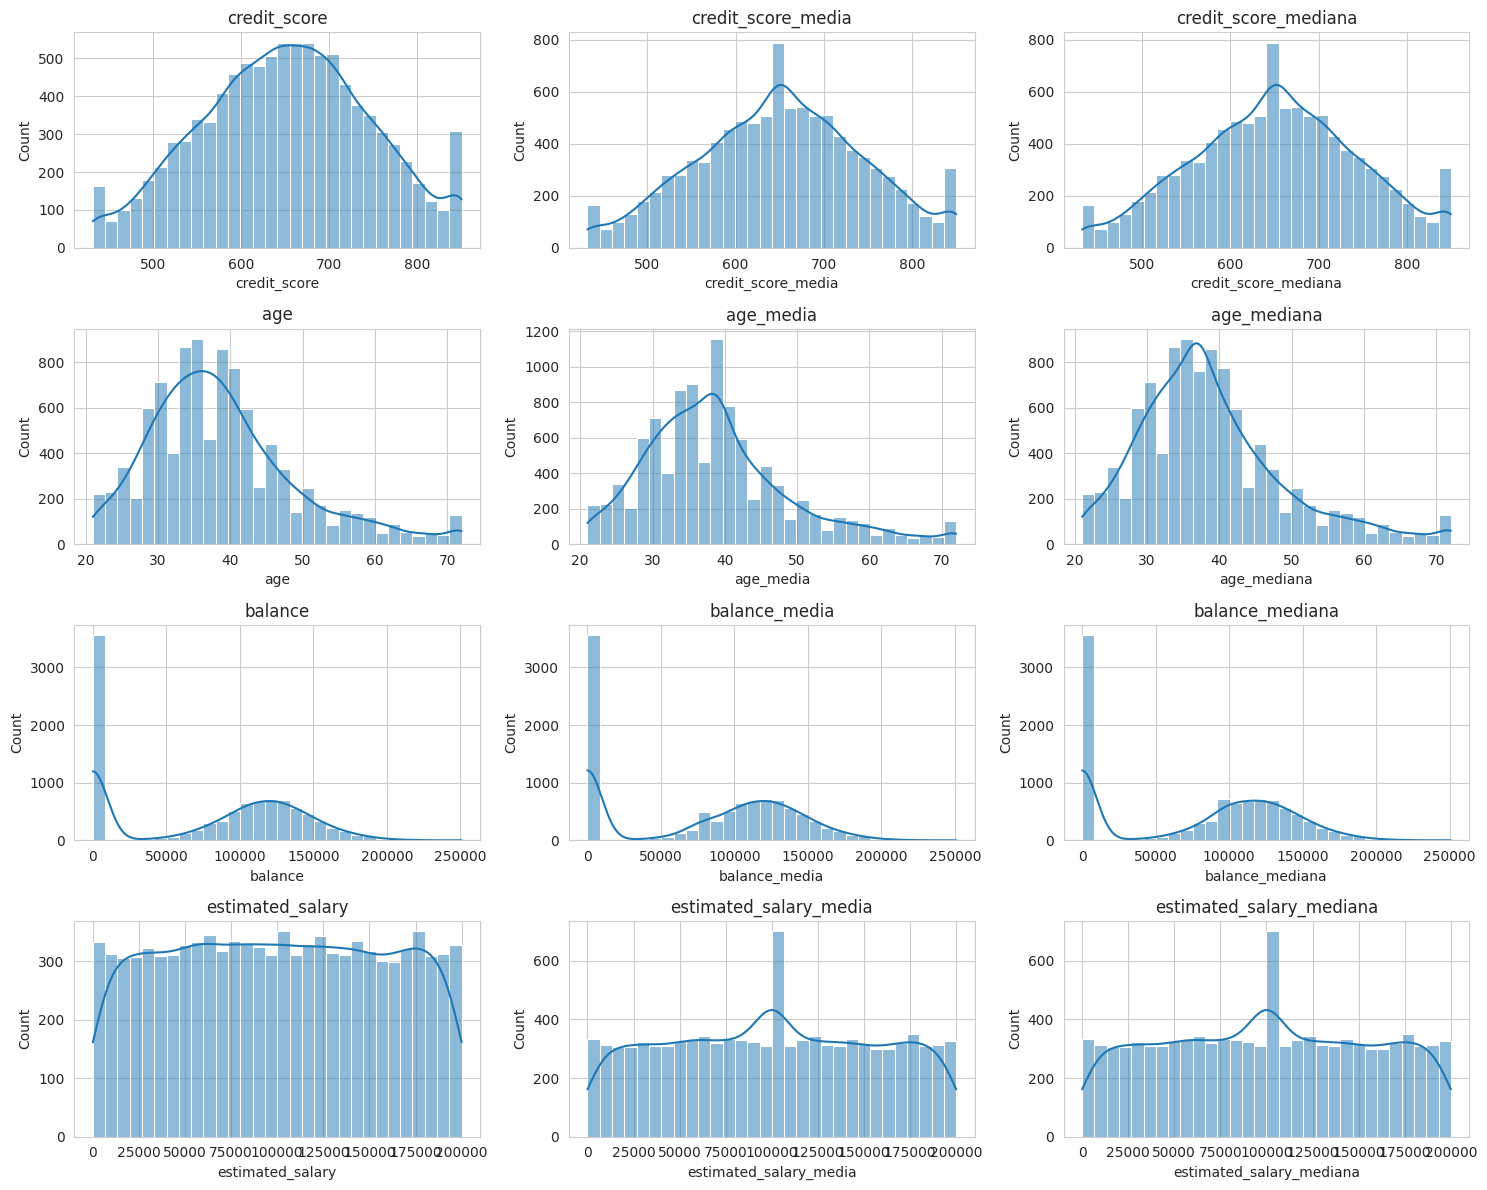

,count,mean,std,min,25%,50%,75%,max
credit_score,9750.0,650.817231,96.195754,432.0,584.0,652.000000,718.0,850.0
credit_score_media,10000.0,650.817231,94.985575,432.0,586.0,650.817231,716.0,850.0
credit_score_mediana,10000.0,650.846800,94.985755,432.0,586.0,652.000000,716.0,850.0


,count,mean,std,min,25%,50%,75%,max
age,9700.0,38.901443,10.329442,21.0,32.0,37.0,44.0,72.0
age_media,10000.0,38.901443,10.173305,21.0,32.0,38.0,44.0,72.0
age_mediana,10000.0,38.844400,10.178475,21.0,32.0,37.0,44.0,72.0


,count,mean,std,min,25%,50%,75%,max
balance,9800.0,76286.251909,62413.450781,0.0,0.0,97038.690,127537.155,250898.09
balance_media,10000.0,76286.251909,61786.100945,0.0,0.0,95504.665,127050.000,250898.09
balance_mediana,10000.0,76701.300671,61854.378361,0.0,0.0,97038.690,127050.000,250898.09


,count,mean,std,min,25%,50%,75%,max
estimated_salary,9650.0,100038.561724,57502.159691,0.0,51012.4725,100129.330000,149370.550,199992.48
estimated_salary_media,10000.0,100038.561724,56486.806887,0.0,52825.6650,100038.561724,147389.735,199992.48
estimated_salary_mediana,10000.0,100041.738614,56486.809350,0.0,52825.6650,100129.330000,147389.735,199992.48


In [183]:
# Nulos: revisión y comparación exploratoria de imputación con media y mediana
# (la imputación final se hará solo con datos de entrenamiento, dentro del pipeline de modelado)
print((df_clean.isna().mean() * 100).round(2))

con_nulos = ['credit_score', 'age', 'balance', 'estimated_salary']  # todos con menos del 5% de nulos
df_imp = df_clean[con_nulos].copy()
for columna in con_nulos:
    df_imp[columna + '_media'] = df_clean[columna].fillna(df_clean[columna].mean())
    df_imp[columna + '_mediana'] = df_clean[columna].fillna(df_clean[columna].median())

# Efecto sobre los histogramas de cada opción
fig, axes = plt.subplots(len(con_nulos), 3, figsize=(15, 3 * len(con_nulos)))
for i, columna in enumerate(con_nulos):
    for j, version in enumerate([columna, columna + '_media', columna + '_mediana']):
        sns.histplot(df_imp[version], bins=30, kde=True, ax=axes[i, j])
        axes[i, j].set_title(version)
plt.tight_layout()
plt.show()

for columna in con_nulos:
    display(df_imp[[columna, columna + '_media', columna + '_mediana']].describe().T)

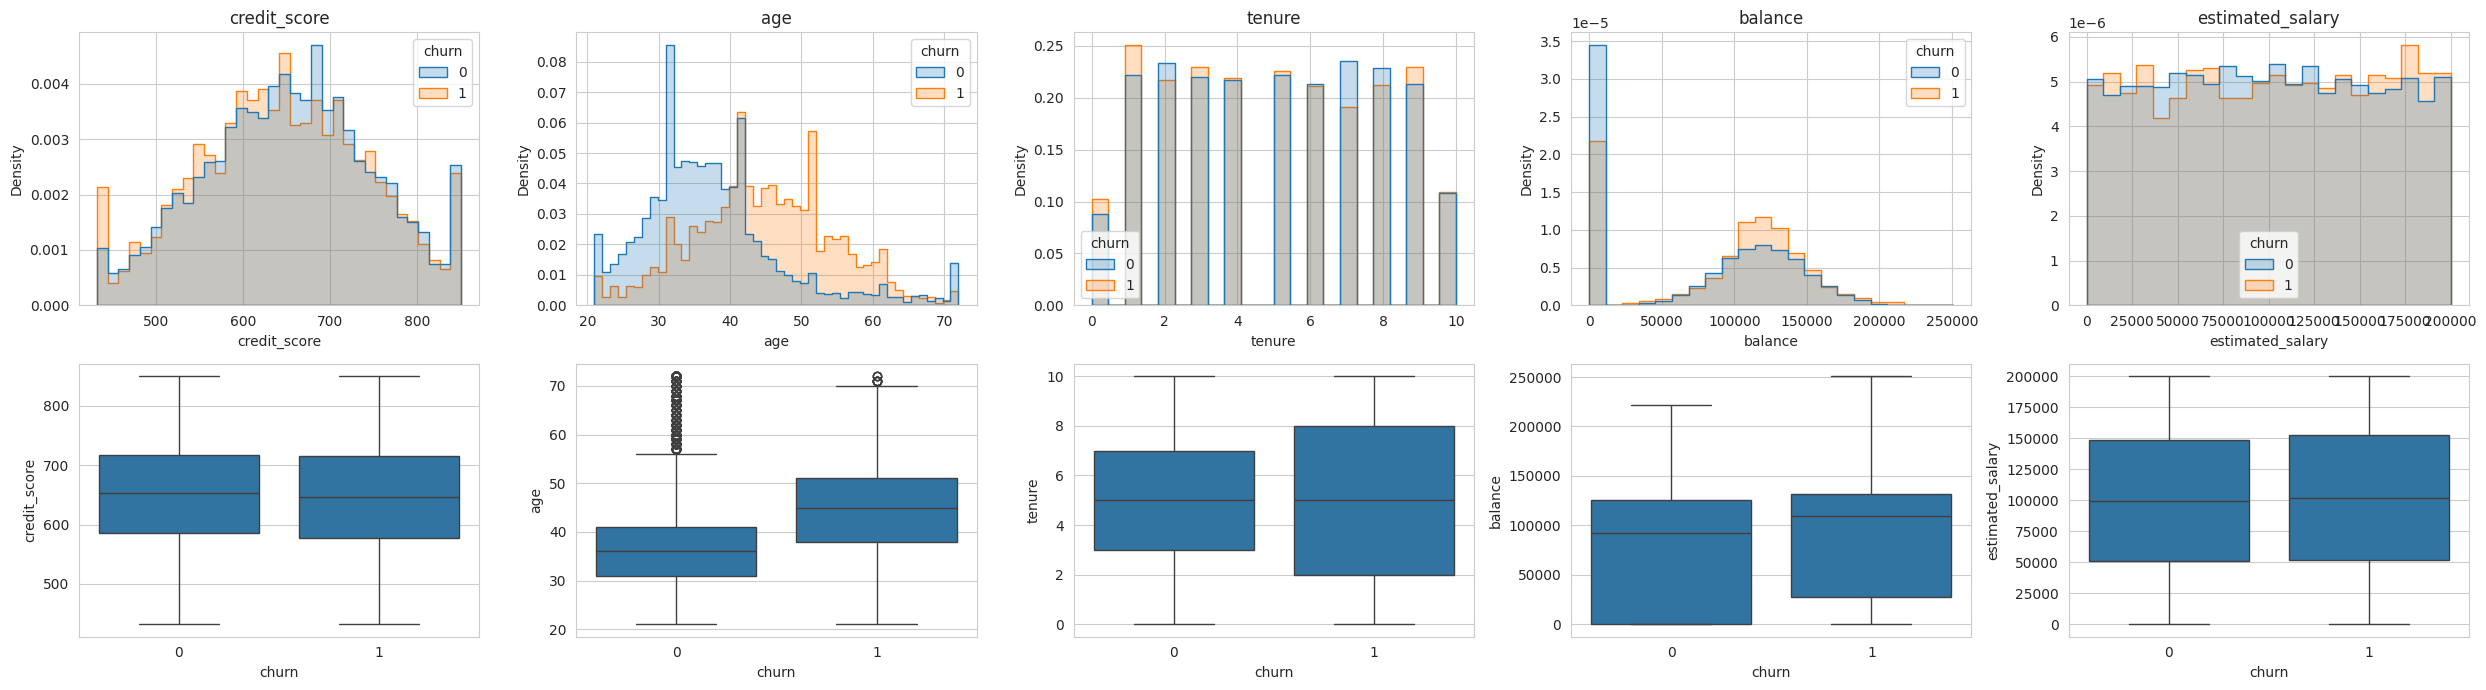

In [184]:
# Variables continuas según el churn: histogramas y cajas por clase
fig, axes = plt.subplots(2, len(continuas), figsize=(5 * len(continuas), 7))
for i, columna in enumerate(continuas):
    sns.histplot(data=df_clean, x=columna, hue=objetivo, stat='density', common_norm=False, element='step', ax=axes[0, i])
    axes[0, i].set_title(columna)
    sns.boxplot(x=objetivo, y=columna, data=df_clean, ax=axes[1, i])
plt.tight_layout()
plt.show()

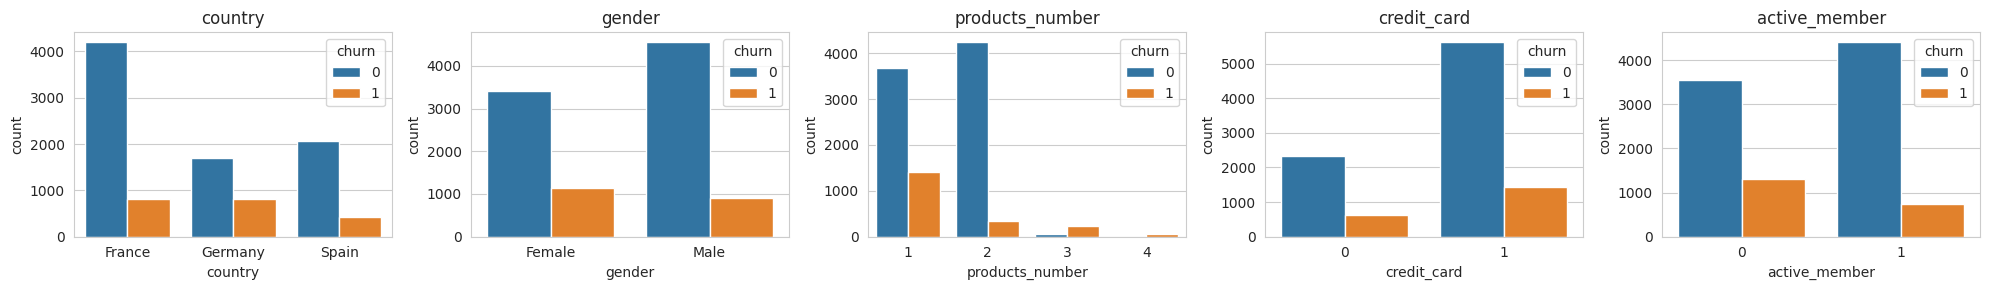

country
France     0.162
Germany    0.324
Spain      0.167
Name: churn, dtype: float64 

gender
Female    0.251
Male      0.165
Name: churn, dtype: float64 

products_number
1    0.277
2    0.076
3    0.827
4    1.000
Name: churn, dtype: float64 

credit_card
0    0.208
1    0.202
Name: churn, dtype: float64 

active_member
0    0.269
1    0.143
Name: churn, dtype: float64 



In [185]:
# Variables categóricas y binarias según el churn
columnas = categoricas + binarias
fig, axes = plt.subplots(1, len(columnas), figsize=(4 * len(columnas), 3))
for ax, columna in zip(axes, columnas):
    sns.countplot(x=columna, hue=objetivo, data=df_clean, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

# Tasa de churn por categoría
for columna in columnas:
    print(df_clean.groupby(columna)[objetivo].mean().round(3), '\n')

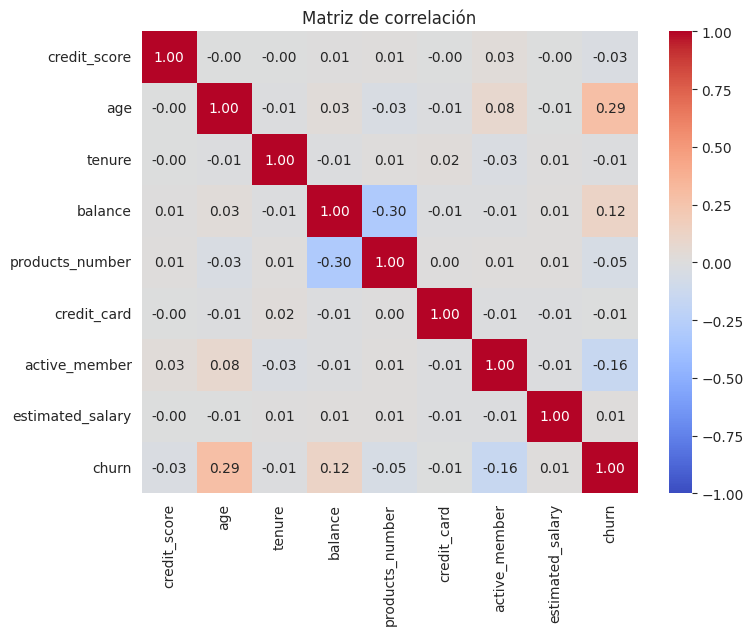

age                 0.287367
active_member      -0.156128
balance             0.117663
products_number    -0.047820
credit_score       -0.025432
tenure             -0.014259
estimated_salary    0.010658
credit_card        -0.007138
Name: churn, dtype: float64


In [186]:
# Matriz de correlación (Pearson) y correlación con el objetivo
corr = df_clean.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

corr_objetivo = corr[objetivo].drop(objetivo)
print(corr_objetivo.reindex(corr_objetivo.abs().sort_values(ascending=False).index))

### Hallazgos del entendimiento de datos

**Tamaño y tipos.** El dataset original tiene 10.045 clientes y 11 columnas: 5 continuas (puntaje de crédito, edad, antigüedad, saldo y salario estimado), 3 categóricas (país, género y número de productos), 2 binarias (tarjeta de crédito y miembro activo) y la variable objetivo `churn`. Después de limpiar quedan 10.000 clientes.

**Problemas de calidad y cómo se trataron**
- 45 filas duplicadas: se eliminaron.
- `country` y `gender` tenían la misma categoría escrita de varias formas (`FRANCE`, `france `, `M`, `F`...): se unificaron.
- Valores fuera del rango válido (edades de 210 años o negativas, antigüedad negativa o de 25 años, salarios negativos, puntajes de crédito de 1200): se llevaron al límite válido más cercano.
- Atípicos: solo `age` y `credit_score` los tenían; se recortaron con los percentiles 1 y 99, y los gráficos de cajas antes y después muestran que el centro de la distribución no cambia.
- Nulos: `credit_score`, `age`, `balance` y `estimated_salary` tienen entre 2% y 4% de nulos. La comparación entre media y mediana fue solo exploratoria. La imputación definitiva se hará con los datos de entrenamiento después de dividir los datos, para no filtrar información de la prueba.

**Indicadores importantes**
- La tasa de churn es de ~20%, más alta que el promedio del sector (~15%). Las clases están desbalanceadas (80/20), por lo que no basta con mirar la exactitud al evaluar los modelos.
- Los clientes que abandonan son claramente **mayores** que los que se quedan (se ve en los histogramas y en las cajas por clase). La edad es la variable numérica más relacionada con el churn.
- **Alemania** tiene un churn de ~32%, el doble que Francia y España (~16%).
- Los clientes **inactivos** abandonan más (27% vs 14%) y las **mujeres** también (25% vs 17%).
- El **número de productos** no tiene un efecto lineal: con 2 productos el churn es muy bajo (~8%), con 1 es ~28% y con 3 o 4 casi todos abandonan (aunque son pocos clientes).
- El saldo, el puntaje de crédito, la antigüedad y el salario casi no se relacionan con el churn por sí solos.

**Implicación para el modelado.** Hay relaciones no lineales (edad, productos), por lo que los modelos basados en árboles podrían ajustarse mejor que uno lineal. Las variables categóricas necesitarán codificación.

## PUNTO 2

### Etapa 1. Codificación de variables

Los modelos solo trabajan con números, así que las variables de texto hay que convertirlas. Primero se separan las variables de entrada (`X`) de lo que se quiere predecir (`churn`, en `y`). Luego `country`, `gender` y `products_number` se transforman con one-hot: cada categoría pasa a ser una columna de 0 y 1, y se elimina una categoría por variable (`drop_first=True`) porque queda implícita en las demás.

El número de productos se trata como categoría y no como número porque, según el análisis del punto 1, su relación con el abandono no es lineal: con 2 productos casi nadie se va, pero con 3 o 4 casi todos se van.

In [187]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Variables de entrada y objetivo
X = df_clean.drop(columns=objetivo)
y = df_clean[objetivo]

# One-hot encoding. products_number se trata como categórica porque su efecto sobre el churn no es lineal
X = pd.get_dummies(X, columns=['country', 'gender', 'products_number'], drop_first=True, dtype=int)
print(X.columns.tolist())

['credit_score', 'age', 'tenure', 'balance', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male', 'products_number_2', 'products_number_3', 'products_number_4']


### Etapa 2. División de los datos

Para saber si un modelo funciona con clientes que no vio, los datos se reparten en tres grupos: **entrenamiento** (60%) para que el modelo aprenda, **validación** (20%) para comparar modelos y ajustar sus configuraciones, y **prueba** (20%) que se guarda intacto hasta el punto 3 para la evaluación final.

La división se hace en dos pasos: primero se aparta el 20% de prueba y, del 80% restante, el 25% se usa para validación (que equivale al 20% del total). Es estratificada, es decir, cada grupo conserva el mismo ~20% de clientes que abandonan, y tiene semilla fija (`random_state=42`) para que el resultado sea reproducible. Al final se imprime la proporción de churn de cada grupo para comprobarlo.

In [188]:
# División estratificada: 60% entrenamiento, 20% validación, 20% prueba
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print('Tamaños:', X_train.shape[0], X_val.shape[0], X_test.shape[0])

# Verificar que la proporción de churn se mantiene en los tres conjuntos
print(y_train.value_counts(normalize=True).round(3))
print(y_val.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

Tamaños: 6000 2000 2000
churn
0    0.796
1    0.204
Name: proportion, dtype: float64
churn
0    0.796
1    0.204
Name: proportion, dtype: float64
churn
0    0.796
1    0.204
Name: proportion, dtype: float64


### Etapa 3. Imputación y escalado

Quedan algunos datos faltantes (entre 2% y 4% en cuatro variables) y las variables están en escalas muy distintas (el saldo llega a cientos de miles y la edad a decenas). Se resuelve así:
- **Imputación:** los nulos se rellenan con la mediana de cada variable, porque no se afecta por valores extremos.
- **Escalado:** con `StandardScaler` cada variable queda con media 0 y desviación 1. Esto es indispensable para KNN y la regresión logística, y no perjudica a los modelos de árboles.

Tanto las medianas como la media y desviación del escalado se calculan **solo con el entrenamiento** y luego se aplican a validación y prueba. Si se calcularan con todos los datos, el modelo recibiría información de clientes que no debería conocer.

In [189]:
# Imputación de nulos con la mediana calculada solo con entrenamiento
medianas = X_train.median()
X_train = X_train.fillna(medianas)
X_val = X_val.fillna(medianas)
X_test = X_test.fillna(medianas)

# Escalado: el escalador se ajusta solo con entrenamiento y se aplica a validación y prueba
escalador = StandardScaler()
X_train_esc = pd.DataFrame(escalador.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_esc = pd.DataFrame(escalador.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns, index=X_test.index)

print('Nulos restantes:', X_train_esc.isna().sum().sum(), X_val_esc.isna().sum().sum(), X_test_esc.isna().sum().sum())

Nulos restantes: 0 0 0


### Etapa 4. Entrenamiento de los modelos

Se prueban cinco modelos de complejidad creciente. Cada uno tiene "perillas" (hiperparámetros) que cambian su comportamiento, y para elegirlas se prueban varias combinaciones con **validación cruzada estratificada de 5 folds**: el entrenamiento se parte en 5 partes, el modelo aprende con 4 y se evalúa en la quinta, y así se rota. El resultado de cada combinación es el promedio de las 5 evaluaciones.

La métrica para elegir es **F1** y no la exactitud. Como solo el 20% de los clientes abandona, un modelo que dijera "nadie se va" tendría 80% de exactitud sin detectar a ningún cliente en riesgo. El F1 combina qué tan bien se detectan los que abandonan (recall) con qué tan confiables son las alertas (precisión).

#### 4.1 Regresión logística
Es el modelo más simple: combina las variables con una fórmula lineal. Sirve como punto de comparación. Se ajusta `C` (qué tanto se controla la complejidad) y `class_weight` (si se le da más peso a los clientes que abandonan para compensar que son pocos).

In [190]:
# Regresión logística: validación cruzada estratificada de 5 folds
# Se optimiza F1 y no la exactitud porque las clases están desbalanceadas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced'],
}
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=cv, scoring='f1', n_jobs=-1)
grid_lr.fit(X_train_esc, y_train)

print('Mejores hiperparámetros:', grid_lr.best_params_)
print('F1 medio en validación cruzada:', round(grid_lr.best_score_, 4))

Mejores hiperparámetros: {'C': 1, 'class_weight': 'balanced'}
F1 medio en validación cruzada: 0.5642


#### 4.2 Árbol de decisión
Hace preguntas sucesivas sobre las variables (por ejemplo, "¿edad mayor a 45?") hasta llegar a un grupo de clientes parecidos. Puede capturar relaciones no lineales, pero un árbol muy profundo memoriza el entrenamiento. Por eso se ajusta `max_depth` (profundidad máxima), `min_samples_leaf` (mínimo de clientes por grupo final) y `class_weight`.

In [191]:
# Árbol de decisión
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_leaf': [1, 5, 20, 50],
    'class_weight': [None, 'balanced'],
}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=cv, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train_esc, y_train)

print('Mejores hiperparámetros:', grid_dt.best_params_)
print('F1 medio en validación cruzada:', round(grid_dt.best_score_, 4))

Mejores hiperparámetros: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 20}
F1 medio en validación cruzada: 0.5708


#### 4.3 KNN (vecinos más cercanos)
Para predecir a un cliente, busca a los clientes más parecidos del entrenamiento y toma la decisión de la mayoría. Como mide distancias entre clientes, depende de que las variables estén escaladas (etapa 3). Se ajusta `n_neighbors` (cuántos vecinos votan) y `weights` (si los vecinos más cercanos pesan más).

In [192]:
# KNN (requiere variables escaladas)
param_grid_knn = {
    'n_neighbors': [3, 5, 11, 21, 41],
    'weights': ['uniform', 'distance'],
}
grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=cv, scoring='f1', n_jobs=-1)
grid_knn.fit(X_train_esc, y_train)

print('Mejores hiperparámetros:', grid_knn.best_params_)
print('F1 medio en validación cruzada:', round(grid_knn.best_score_, 4))

Mejores hiperparámetros: {'n_neighbors': 5, 'weights': 'uniform'}
F1 medio en validación cruzada: 0.5183


#### 4.4 Random Forest
Entrena muchos árboles, cada uno con una muestra distinta de clientes y de variables, y promedia sus respuestas. Eso lo hace más estable que un solo árbol. Se ajusta el número de árboles (`n_estimators`), la profundidad (`max_depth`), el mínimo de clientes por hoja (`min_samples_leaf`) y `class_weight`. La cuadrícula es pequeña para que la búsqueda no tarde demasiado.

In [193]:

# Random Forest
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10],
    'min_samples_leaf': [5, 20],
    'class_weight': [None, 'balanced'],
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_rf.fit(X_train_esc, y_train)

print('Mejores hiperparámetros:', grid_rf.best_params_)
print('F1 medio en validación cruzada:', round(grid_rf.best_score_, 4))

Mejores hiperparámetros: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 medio en validación cruzada: 0.6202


#### 4.5 Gradient Boosting
Construye árboles pequeños uno detrás de otro, y cada árbol intenta corregir los errores del anterior. Se ajusta `learning_rate` (qué tanto aporta cada árbol nuevo) y `max_depth`.

Este modelo no tiene `class_weight`, así que para compensar el desbalance se le pasan pesos por cliente (`compute_sample_weight('balanced')`), que dan más importancia a los que abandonan. Con esos pesos, `GridSearchCV` calcula un F1 inflado, por eso la validación cruzada se hace con un ciclo propio que calcula el F1 sin ponderar y muestra el avance. La cuadrícula es de solo 4 combinaciones para acortar el tiempo.

In [194]:
# Gradient Boosting: no tiene class_weight, por eso se usan pesos por registro balanceados.
# La validación cruzada se hace a mano para que el F1 se calcule sin ponderar
# (con sample_weight dentro de GridSearchCV el F1 de validación cruzada sale inflado).
# Cuadrícula reducida (4 combinaciones) para acortar el tiempo; se muestra el avance.
cuadricula_gb = list(ParameterGrid({
    'n_estimators': [100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4],
}))

resultados_gb = []
for i, params in enumerate(cuadricula_gb, start=1):
    f1_folds = []
    for idx_ent, idx_val in cv.split(X_train_esc, y_train):
        pesos = compute_sample_weight('balanced', y_train.iloc[idx_ent])
        m = GradientBoostingClassifier(random_state=42, **params)
        m.fit(X_train_esc.iloc[idx_ent], y_train.iloc[idx_ent], sample_weight=pesos)
        f1_folds.append(f1_score(y_train.iloc[idx_val], m.predict(X_train_esc.iloc[idx_val])))
    resultados_gb.append({**params, 'F1 cv': np.mean(f1_folds)})
    print(f'\rCompletado: {i / len(cuadricula_gb):.0%}', end='', flush=True)

resultados_gb = pd.DataFrame(resultados_gb).sort_values('F1 cv', ascending=False)
print()
display(resultados_gb)
mejores_gb = resultados_gb.iloc[0].drop('F1 cv').to_dict()
mejores_gb['n_estimators'] = int(mejores_gb['n_estimators'])
mejores_gb['max_depth'] = int(mejores_gb['max_depth'])
print('Mejores hiperparámetros:', mejores_gb)

# Se reentrena con todo el conjunto de entrenamiento
modelo_gb = GradientBoostingClassifier(random_state=42, **mejores_gb)
modelo_gb.fit(X_train_esc, y_train, sample_weight=compute_sample_weight('balanced', y_train))

Completado: 100%


,learning_rate,max_depth,n_estimators,F1 cv
3,0.10,4,100,0.621460
1,0.05,4,100,0.613945
2,0.10,3,100,0.612599
0,0.05,3,100,0.608077


Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,4
,min_impurity_decrease,0.0
,init,None


### Etapa 5. Comparación y selección del modelo

Con la mejor configuración de cada modelo ya definida, se comparan sobre los mismos datos. Se calculan cuatro métricas (exactitud, precisión, recall y F1) tanto en entrenamiento como en validación. La diferencia de F1 entre ambos (`Brecha F1`) indica sobreajuste: si un modelo rinde mucho mejor en entrenamiento que en validación, está memorizando en vez de aprender.

El modelo se elige por su **F1 en validación**, nunca con el conjunto de prueba, que sigue sin tocarse.

,Exactitud train,Precisión train,Recall train,F1 train,Exactitud val,Precisión val,Recall val,F1 val,Brecha F1
Modelo,,,,,,,,,
Regresión logística,0.764,0.453,0.747,0.564,0.757,0.441,0.727,0.549,0.015
Árbol de decisión,0.877,0.763,0.576,0.657,0.844,0.667,0.467,0.549,0.108
KNN,0.881,0.800,0.554,0.655,0.825,0.610,0.388,0.474,0.180
Random Forest,0.877,0.658,0.826,0.733,0.812,0.531,0.636,0.579,0.154
Gradient Boosting,0.852,0.598,0.836,0.698,0.798,0.502,0.708,0.587,0.110


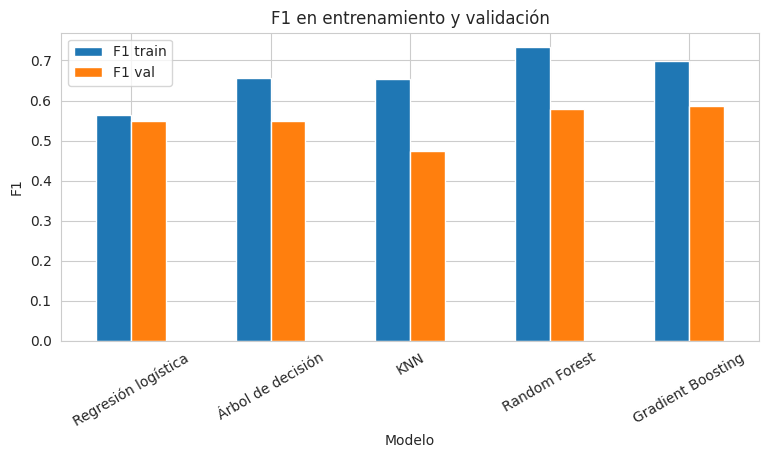

Modelo seleccionado: Gradient Boosting


In [195]:
# Comparación en entrenamiento y validación
modelos = {
    'Regresión logística': grid_lr.best_estimator_,
    'Árbol de decisión': grid_dt.best_estimator_,
    'KNN': grid_knn.best_estimator_,
    'Random Forest': grid_rf.best_estimator_,
    'Gradient Boosting': modelo_gb,
}

def calcular_metricas(modelo, X, y):
    y_pred = modelo.predict(X)
    return {
        'Exactitud': accuracy_score(y, y_pred),
        'Precisión': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1': f1_score(y, y_pred),
    }

filas = []
for nombre, modelo in modelos.items():
    train = calcular_metricas(modelo, X_train_esc, y_train)
    val = calcular_metricas(modelo, X_val_esc, y_val)
    fila = {'Modelo': nombre}
    fila.update({f'{k} train': v for k, v in train.items()})
    fila.update({f'{k} val': v for k, v in val.items()})
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index('Modelo')
tabla['Brecha F1'] = tabla['F1 train'] - tabla['F1 val']
display(tabla.round(3))

# Gráfico de F1 en entrenamiento y validación
tabla[['F1 train', 'F1 val']].plot(kind='bar', figsize=(9, 4))
plt.ylabel('F1')
plt.title('F1 en entrenamiento y validación')
plt.xticks(rotation=30)
plt.show()

# Selección: mayor F1 en validación (el conjunto de prueba no se usa aquí)
mejor_modelo = tabla['F1 val'].idxmax()
print('Modelo seleccionado:', mejor_modelo)

### Resultado del punto 2: modelo seleccionado

**Configuraciones elegidas** (F1 medio en validación cruzada):

| Modelo | Mejores hiperparámetros | F1 cv |
|---|---|---|
| Regresión logística | `C=1`, `class_weight='balanced'` | 0,564 |
| Árbol de decisión | `max_depth=None`, `min_samples_leaf=20` | 0,571 |
| KNN | `n_neighbors=5`, `weights='uniform'` | 0,518 |
| Random Forest | `n_estimators=200`, `max_depth=10`, `min_samples_leaf=5`, `class_weight='balanced'` | 0,620 |
| Gradient Boosting | `learning_rate=0.1`, `max_depth=4`, `n_estimators=100` (con pesos balanceados) | 0,621 |

**Qué se ve en la comparación**
- **Gradient Boosting** tiene el mayor F1 en validación (0,587), seguido de cerca por Random Forest (0,579). La diferencia es muy pequeña, así que en la práctica son equivalentes en calidad.
- Entre los dos, Gradient Boosting se sobreajusta menos (brecha de F1 de 0,110 frente a 0,154) y detecta más clientes que abandonan (recall de 0,708 frente a 0,636). Por eso la elección es razonable.
- **KNN** es el que más se sobreajusta (brecha de 0,180): en entrenamiento parece bueno, pero en validación solo detecta al 39% de los que abandonan.
- **Árbol de decisión** es más preciso (0,667) pero detecta menos clientes que abandonan (recall de 0,467).
- **Regresión logística** es la más estable (brecha de 0,015) y la que más clientes detecta entre los modelos simples, pero con muchas falsas alarmas (precisión de 0,441).

**Limitaciones de este entrenamiento**
- Las cuadrículas de Random Forest y Gradient Boosting son pequeñas para ahorrar tiempo, y las mejores combinaciones de Gradient Boosting quedaron en el borde de lo probado (`learning_rate=0.1` y `max_depth=4`), así que podrían mejorar con más búsqueda.
- Los percentiles del recorte de atípicos del punto 1 se calcularon con todos los datos antes de dividir. El efecto es pequeño, pero no es estrictamente limpio.
- Se usaron todas las variables sin una selección previa con pruebas estadísticas.
- El conjunto de prueba sigue sin usarse. En el punto 3 se evaluará el modelo elegido con él.

## PUNTO 3. Análisis cuantitativo de resultados del modelo

### Etapa 1. Curvas ROC y precisión-recall

Hasta ahora evalué cada modelo con un solo corte, el de 0,5. Para ver cómo se comportan en general dibujo dos curvas, una para entrenamiento y otra para validación. La curva ROC me dice qué tan bien separa el modelo a los clientes que se van de los que se quedan: un AUC de 0,5 sería lanzar una moneda y 1 sería separarlos perfecto. La curva precisión-recall me muestra qué tan confiables son las alertas a medida que le pido al modelo detectar más clientes; su línea base es la proporción de clientes que abandonan (cerca de 20%) y, con clases tan desbalanceadas, es la más exigente de las dos. Comparar entrenamiento contra validación también me ayuda a ver cuáles modelos están memorizando.

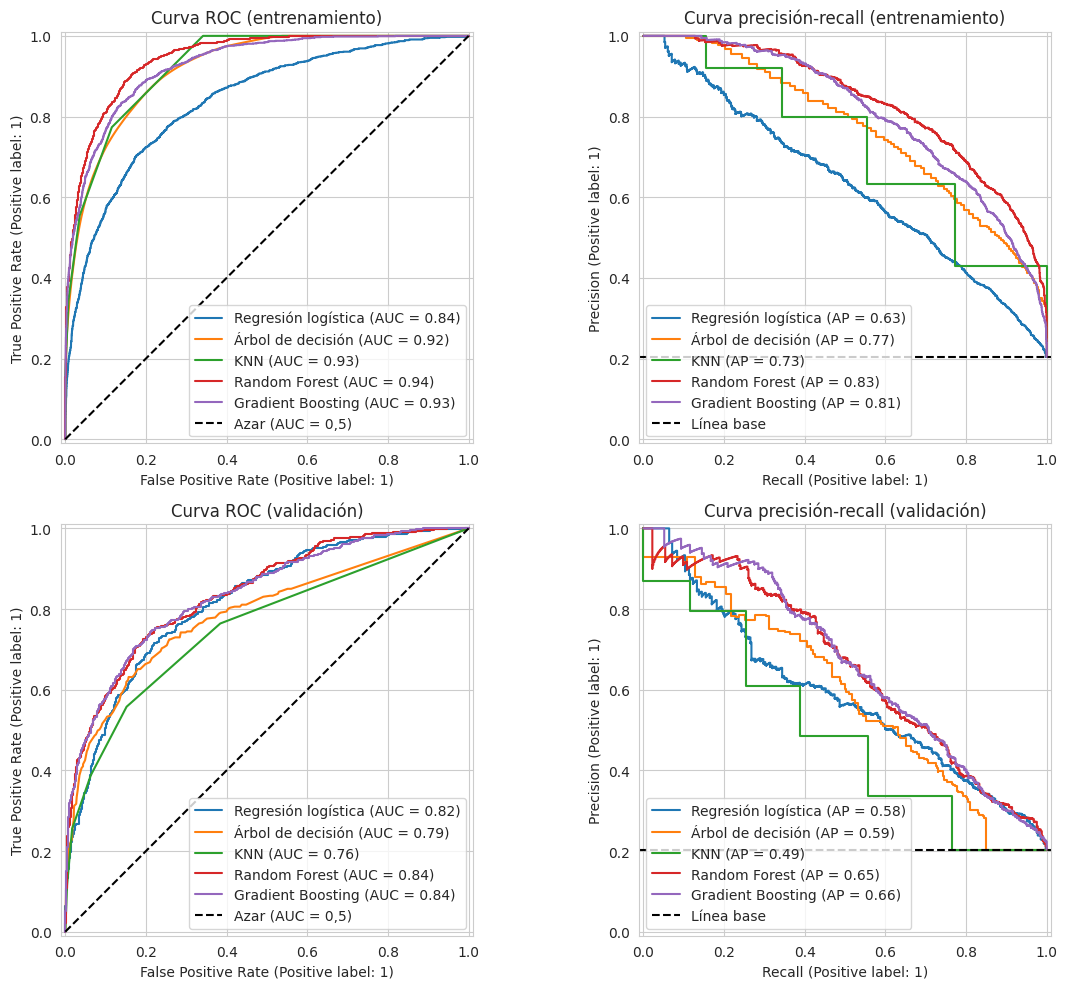

AUC                       AP           
Conjunto            entrenamiento validación entrenamiento validación
Modelo                                                               
Gradient Boosting           0.928      0.837         0.808      0.663
KNN                         0.926      0.756         0.733      0.492
Random Forest               0.945      0.839         0.834      0.654
Regresión logística         0.839      0.818         0.633      0.585
Árbol de decisión           0.919      0.786         0.768      0.587

In [196]:
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, RocCurveDisplay,
                             PrecisionRecallDisplay, roc_auc_score, average_precision_score)

# Curvas ROC y precisión-recall de los cinco modelos, en entrenamiento (fila de arriba) y validación (fila de abajo)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
filas = []
for f, (conjunto, X_c, y_c) in enumerate([('entrenamiento', X_train_esc, y_train), ('validación', X_val_esc, y_val)]):
    for nombre, modelo in modelos.items():
        RocCurveDisplay.from_estimator(modelo, X_c, y_c, ax=axes[f, 0], name=nombre)
        PrecisionRecallDisplay.from_estimator(modelo, X_c, y_c, ax=axes[f, 1], name=nombre)
        y_prob = modelo.predict_proba(X_c)[:, 1]
        filas.append({'Conjunto': conjunto, 'Modelo': nombre,
                      'AUC': roc_auc_score(y_c, y_prob), 'AP': average_precision_score(y_c, y_prob)})
    axes[f, 0].plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0,5)')
    axes[f, 1].axhline((y_c == 1).mean(), color='k', linestyle='--', label='Línea base')
    axes[f, 0].set_title(f'Curva ROC ({conjunto})')
    axes[f, 1].set_title(f'Curva precisión-recall ({conjunto})')
    axes[f, 0].legend()
    axes[f, 1].legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(filas).pivot(index='Modelo', columns='Conjunto', values=['AUC', 'AP']).round(3))

### Etapa 2. Matrices de confusión

Aquí cuento, para cada modelo en validación, cuántos clientes que se van logra detectar, cuántos se le escapan, cuántas falsas alarmas genera y cuántos clientes que se quedan reconoce bien. Las filas son lo que realmente pasó y las columnas lo que el modelo predijo.

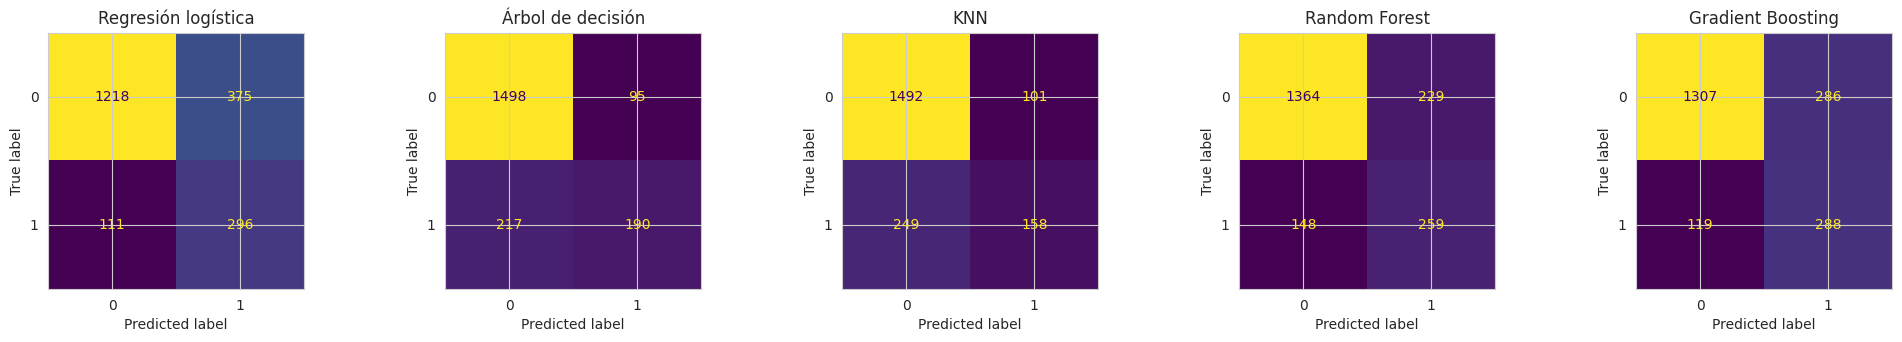

In [197]:
# Matrices de confusión en validación (conteos)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_val_esc, y_val, ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

### Etapa 3. Evaluación final en prueba

Con el modelo ya elegido uso por primera y única vez los 2.000 clientes de prueba, que el modelo nunca ha visto. Miro su matriz de confusión, comparo las métricas con las de validación (si se mantienen, el modelo generaliza) y comparo la exactitud con la de un modelo "tonto" que siempre diga que el cliente no se va.

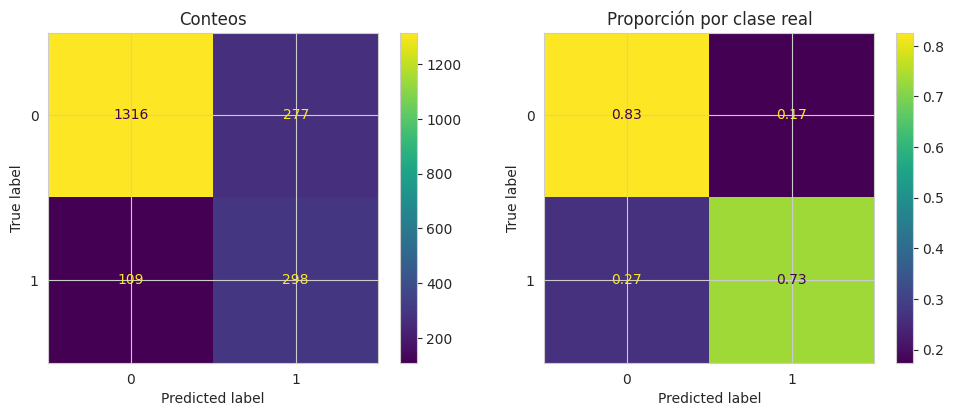

Verdaderos positivos: 298 | Falsos negativos: 109 | Falsos positivos: 277 | Verdaderos negativos: 1316


,Validación,Prueba
Exactitud,0.798,0.807
Precisión,0.502,0.518
Recall,0.708,0.732
F1,0.587,0.607
AUC,0.837,0.862
AP,0.663,0.701


Exactitud de predecir siempre "no abandona": 0.796


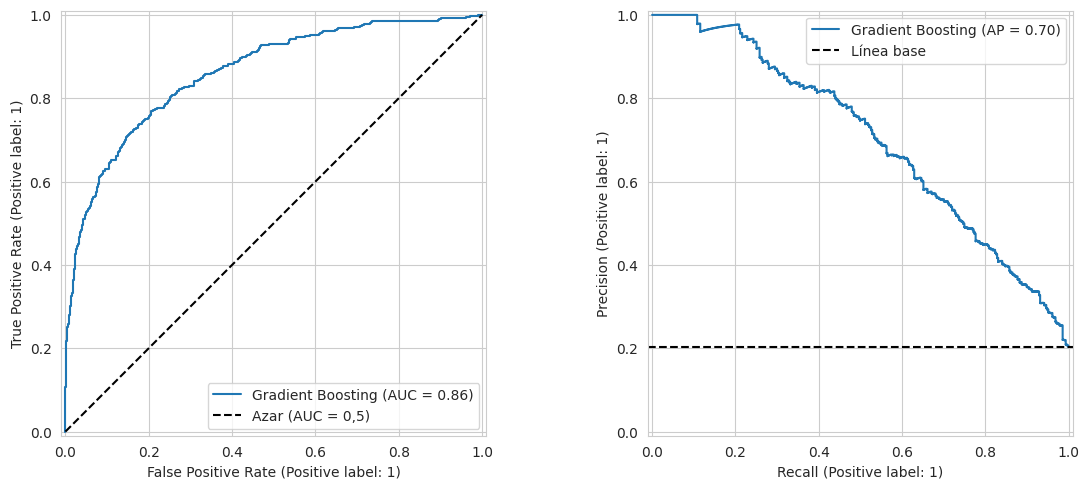

In [198]:
# Evaluación final en prueba del modelo elegido (única vez que se usa este conjunto)
modelo_final = modelos[mejor_modelo]
y_pred_test = modelo_final.predict(X_test_esc)
y_prob_test = modelo_final.predict_proba(X_test_esc)[:, 1]

# Matriz de confusión: conteos y proporción por clase real
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, ax=axes[0])
axes[0].set_title('Conteos')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, normalize='true', ax=axes[1])
axes[1].set_title('Proporción por clase real')
plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, y_pred_test).ravel()
print(f'Verdaderos positivos: {vp} | Falsos negativos: {fn} | Falsos positivos: {fp} | Verdaderos negativos: {vn}')

# Métricas en validación y prueba
comparacion = pd.DataFrame({
    'Validación': calcular_metricas(modelo_final, X_val_esc, y_val),
    'Prueba': calcular_metricas(modelo_final, X_test_esc, y_test),
})
comparacion.loc['AUC'] = [roc_auc_score(y_val, modelo_final.predict_proba(X_val_esc)[:, 1]), roc_auc_score(y_test, y_prob_test)]
comparacion.loc['AP'] = [average_precision_score(y_val, modelo_final.predict_proba(X_val_esc)[:, 1]), average_precision_score(y_test, y_prob_test)]
display(comparacion.round(3))

# Línea base: un modelo que siempre responde "no abandona"
print('Exactitud de predecir siempre "no abandona":', round((y_test == 0).mean(), 3))

# Curvas ROC y precisión-recall en prueba
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_prob_test, ax=axes[0], name=mejor_modelo)
axes[0].plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0,5)')
PrecisionRecallDisplay.from_predictions(y_test, y_prob_test, ax=axes[1], name=mejor_modelo)
axes[1].axhline((y_test == 1).mean(), color='k', linestyle='--', label='Línea base')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

### Análisis de resultados del punto 3

Empiezo por lo que significan los números en el conjunto de prueba, donde hay 2.000 clientes y 407 de ellos se van. El modelo acierta en el 80,7% de los casos, pero eso engaña: uno que siempre dijera "no se va" acertaría el 79,6%, así que la exactitud casi no dice nada cuando las clases están tan desbalanceadas. Lo que sí importa es qué pasa con los clientes que se van. El modelo detecta 298 de los 407 (recall de 0,73) y los otros 109 se le escapan, que son ingresos que se pierden sin haber podido ofrecerles nada. Por el otro lado, de cada 100 clientes que marca en riesgo, 52 realmente se iban a ir (precisión de 0,52); los otros 48, que en total son 277, son falsas alarmas, es decir, contactos que el banco paga sin necesidad. El F1 de 0,61 resume ese equilibrio. El AUC de 0,86 quiere decir que, si tomo un cliente que se va y uno que se queda, el modelo le asigna más riesgo al primero el 86% de las veces, y la precisión promedio de 0,70 es unas 3,4 veces la línea base de 0,20.

Estas métricas en prueba son iguales o un poco mejores que las de validación (el F1 pasa de 0,59 a 0,61 y el AUC de 0,84 a 0,86), así que el modelo generaliza bien y no se ajustó de más a la validación. La pequeña mejora seguramente se debe al azar de la muestra.

Elegí Gradient Boosting por varias razones. Tiene el mayor F1 (0,587) y la mayor precisión promedio (0,663) en validación, y su AUC (0,837) casi empata con el de Random Forest (0,839). Además se sobreajusta menos que Random Forest (brecha de F1 de 0,11 frente a 0,15) y detecta más clientes que se van. Las curvas lo confirman: en entrenamiento Random Forest, KNN y Gradient Boosting llegan a AUC de 0,93 o más y en validación caen, KNN hasta 0,76, mientras que la regresión logística casi no cambia (de 0,84 a 0,82), pero separa peor. El árbol y KNN dejan escapar a más de la mitad de los clientes que se van (recall de 0,47 y 0,39). Aun así, la diferencia entre Gradient Boosting y Random Forest es pequeña y no la probé estadísticamente, así que cualquiera de los dos sería razonable.

Lo que más ayudó a las métricas fue darle más peso a los clientes que se van, porque sin eso los modelos tienden a ignorarlos: los modelos con pesos tienen un recall alto en validación (0,71 en Gradient Boosting y 0,73 en regresión logística), mientras que el árbol, que quedó sin pesos, detecta solo el 47%. También ayudó usar modelos de árboles, que capturan relaciones que no son lineales, como las de la edad y el número de productos que vi en el punto 1, y la preparación de los datos: la limpieza, tratar el número de productos como categoría y escoger los hiperparámetros con validación cruzada optimizando F1.

Veo varias oportunidades de mejora. El corte de 0,5 no tiene por qué ser el más rentable, porque depende de lo que cuesta cada error, y eso lo ajusto en el punto 5. El modelo solo ve 13 columnas, así que datos de movimientos, uso de los productos o quejas probablemente separarían mejor a los clientes. Las cuadrículas de hiperparámetros fueron pequeñas y algunos de los mejores valores quedaron en el borde de lo que probé. Como entrené con pesos, las probabilidades del modelo no son el riesgo real de cada cliente: sirven para ordenarlos, pero habría que calibrarlas para leerlas como porcentajes. Y para saber si la diferencia entre Gradient Boosting y Random Forest es real habría que usar intervalos de confianza con bootstrapping, como en la práctica 4.

## PUNTO 4. Análisis cualitativo de resultados del modelo

Para entender cómo decide el modelo uso tres técnicas de la práctica 5: los gráficos ICE, que muestran qué pasa con la predicción cuando muevo una variable en muchos clientes a la vez; LIME, que explica la predicción de un cliente en particular; y SHAP, que reparte la predicción entre las variables, tanto para un cliente como para todo el conjunto.

### Etapa 1. Función de predicción con variables originales

Para que las explicaciones se entiendan, tengo que mover variables que tengan sentido para una persona, como la edad, el saldo o el número de productos, y no columnas escaladas o de one-hot. Por eso creo una función que recibe al cliente con sus variables originales y, por dentro, aplica las mismas transformaciones del entrenamiento (el one-hot de productos y el escalado, usando solo `transform` y nunca ajustando de nuevo) antes de llamar al modelo. Al final compruebo que da exactamente las mismas probabilidades que el modelo.

In [199]:
# Función de predicción: recibe las variables originales del cliente (products_number de 1 a 4)
# y aplica las mismas transformaciones del entrenamiento: one-hot de productos, escalado y modelo.
columnas_originales = ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card',
                       'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male']

def a_originales(X):
    """Vuelve el one-hot de productos a un solo número de productos."""
    O = X.drop(columns=['products_number_2', 'products_number_3', 'products_number_4']).copy()
    O['products_number'] = 1 + X['products_number_2'] + 2 * X['products_number_3'] + 3 * X['products_number_4']
    return O[columnas_originales]

def predecir_abandono(X):
    X = pd.DataFrame(X, columns=columnas_originales)
    for k in [2, 3, 4]:
        X[f'products_number_{k}'] = (X['products_number'] == k).astype(int)
    X = X.drop(columns='products_number')[X_train.columns]
    return modelo_final.predict_proba(escalador.transform(X))[:, 1]

X_train_orig = a_originales(X_train)
X_test_orig = a_originales(X_test)

# Verificación: la función debe dar lo mismo que el modelo con los datos ya transformados
print(np.allclose(predecir_abandono(X_test_orig), modelo_final.predict_proba(X_test_esc)[:, 1]))

True


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


### Etapa 2. Gráficos ICE

Un gráfico ICE toma a un cliente, va cambiando el valor de una sola variable (por ejemplo la edad), deja todo lo demás igual y dibuja cómo cambia la probabilidad de abandono. Cada línea es un cliente, así que puedo ver si el efecto es parecido para todos (líneas paralelas) o si depende de otras características (líneas que se cruzan o se separan).

Uso 200 clientes de prueba con la edad, el saldo y el número de productos. Después repito la edad en versión centrada, para comparar la forma de las curvas sin importar dónde empiezan, y por último la separo entre miembros activos e inactivos, con la misma rejilla de edades, para ver si el efecto de la edad cambia según la actividad.

/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingCla

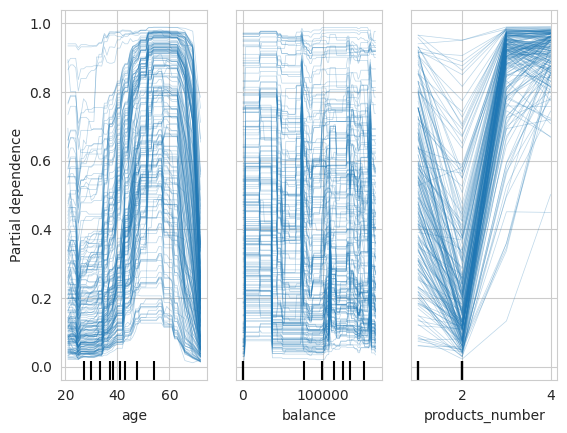

/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingCla

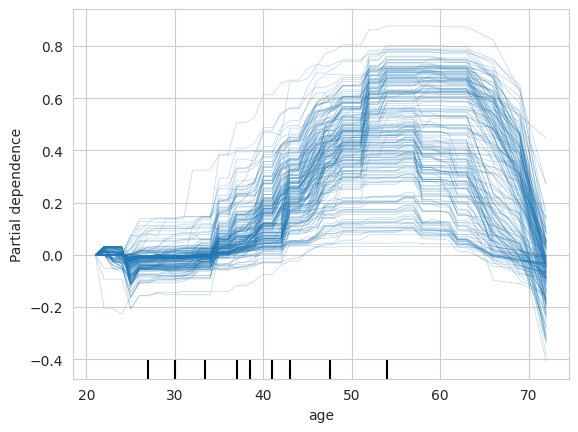

In [200]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import PartialDependenceDisplay

# Envoltorio para que scikit-learn pueda usar la función de predicción
class ClasificadorDesdeFuncion(ClassifierMixin, BaseEstimator):
    def __init__(self, funcion=None):
        self.funcion = funcion

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.funcion(X)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.funcion(X) >= 0.5).astype(int)

clasificador = ClasificadorDesdeFuncion(predecir_abandono).fit(X_train_orig)

# ICE de 200 clientes de prueba: edad, saldo y número de productos
X_muestra = X_test_orig.sample(200, random_state=42).astype(float)
PartialDependenceDisplay.from_estimator(clasificador, X_muestra, ['age', 'balance', 'products_number'], kind='individual')
plt.show()

# La edad otra vez, pero centrada: todas las curvas parten de 0 para comparar su forma
PartialDependenceDisplay.from_estimator(clasificador, X_muestra, ['age'], kind='individual', centered=True)
plt.show()

/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingCla

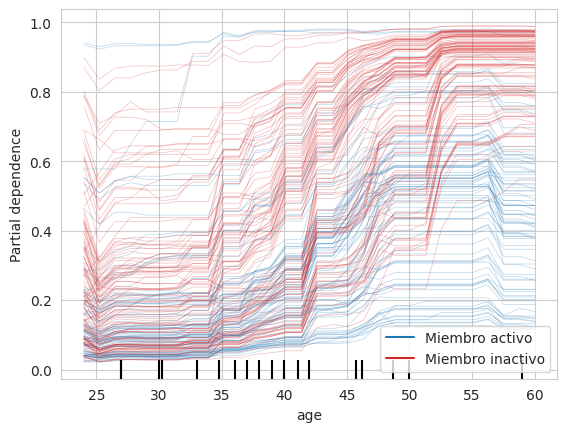

In [201]:
from matplotlib.lines import Line2D

# Misma rejilla de edades para activos e inactivos, para poder comparar las curvas
rejilla = {X_muestra.columns.get_loc('age'): np.linspace(X_muestra['age'].quantile(0.05),
                                                         X_muestra['age'].quantile(0.95), 30)}
activo = X_muestra['active_member'] == 1

grafico = PartialDependenceDisplay.from_estimator(clasificador, X_muestra[activo], ['age'], kind='individual',
                                                  custom_values=rejilla, ice_lines_kw={'color': 'tab:blue', 'alpha': 0.3})
PartialDependenceDisplay.from_estimator(clasificador, X_muestra[~activo], ['age'], kind='individual',
                                        custom_values=rejilla, ax=grafico.axes_,
                                        ice_lines_kw={'color': 'tab:red', 'alpha': 0.3})
grafico.axes_[0, 0].legend(handles=[Line2D([], [], color='tab:blue', label='Miembro activo'),
                                    Line2D([], [], color='tab:red', label='Miembro inactivo')])
plt.show()

### Etapa 3. LIME

LIME explica una sola predicción. Crea muchos clientes parecidos al que quiero explicar, cambiándoles los valores al azar, le pregunta al modelo qué predice para cada uno y ajusta con eso una regresión lineal sencilla. Los pesos de esa regresión me dicen qué variables empujaron la predicción hacia arriba (si son positivos) o hacia abajo (si son negativos) en ese cliente.

Explico tres casos del conjunto de prueba: un cliente que se va y el modelo detectó (verdadero positivo), uno que se va y el modelo no detectó (falso negativo) y uno que se queda pero el modelo marcó en riesgo (falsa alarma). Muestro las 6 variables más influyentes y el R² local, que me dice qué tan bien el modelo sencillo imita al modelo real cerca de ese cliente; si es bajo, hay que desconfiar de la explicación. Al final repito la explicación del verdadero positivo con cinco semillas distintas y con 1.000 y 5.000 simulaciones, para ver si el resultado es estable.

In [202]:
# Si no están instaladas: !pip install lime shap
from lime.lime_tabular import LimeTabularExplainer

# Tres casos del conjunto de prueba (modelo elegido, umbral 0,5)
pred = modelo_final.predict(X_test_esc)
y_real = y_test.to_numpy()
casos = {
    'Verdadero positivo': np.where((y_real == 1) & (pred == 1))[0][0],
    'Falso negativo': np.where((y_real == 1) & (pred == 0))[0][0],
    'Falsa alarma': np.where((y_real == 0) & (pred == 1))[0][0],
}

# LIME necesita la probabilidad de las dos clases
def predecir_proba(X):
    p = predecir_abandono(X)
    return np.column_stack([1 - p, p])

# Variables binarias (0/1) que LIME debe tratar como categóricas
binarias_lime = ['credit_card', 'active_member', 'country_Germany', 'country_Spain', 'gender_Male']
indices_binarias = [columnas_originales.index(c) for c in binarias_lime]

explicador_lime = LimeTabularExplainer(X_train_orig.to_numpy(), feature_names=columnas_originales,
                                       class_names=['No abandona', 'Abandona'], mode='classification',
                                       categorical_features=indices_binarias, random_state=42)

for nombre, i in casos.items():
    explicacion = explicador_lime.explain_instance(X_test_orig.iloc[i].to_numpy(), predecir_proba,
                                                   num_features=6, num_samples=5000)
    prob = predecir_abandono(X_test_orig.iloc[[i]])[0]
    print(f'--- {nombre} (cliente {i}) | probabilidad del modelo: {prob:.2f} | R² local: {explicacion.score:.2f}')
    for variable, peso in explicacion.as_list():
        print(f'   {variable}: {peso:+.3f}')

/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingCla

--- Verdadero positivo (cliente 10) | probabilidad del modelo: 0.88 | R² local: 0.66
   age > 44.00: +0.392
   active_member=0: +0.176
   country_Germany=0: -0.090
   gender_Male=1: -0.089
   balance <= 0.00: +0.082
   5.00 < tenure <= 7.00: -0.010
--- Falso negativo (cliente 18) | probabilidad del modelo: 0.33 | R² local: 0.24
   active_member=0: +0.160
   32.00 < age <= 37.00: -0.148
   gender_Male=1: -0.091
   country_Germany=0: -0.085
   0.00 < balance <= 96007.24: -0.057
   estimated_salary > 149669.93: +0.024
--- Falsa alarma (cliente 5) | probabilidad del modelo: 0.74 | R² local: 0.22
   active_member=0: +0.174
   balance <= 0.00: +0.093
   country_Germany=0: -0.082
   gender_Male=0: +0.080
   37.00 < age <= 44.00: +0.066
   102220.58 < estimated_salary <= 149669.93: -0.016


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [203]:
# Estabilidad de LIME: se explica el verdadero positivo con 5 semillas, con 1.000 y con 5.000 simulaciones
i = casos['Verdadero positivo']
for n in [1000, 5000]:
    print(f'--- {n} simulaciones')
    for semilla in range(5):
        explicador = LimeTabularExplainer(X_train_orig.to_numpy(), feature_names=columnas_originales,
                                          class_names=['No abandona', 'Abandona'], mode='classification',
                                          categorical_features=indices_binarias, random_state=semilla)
        exp = explicador.explain_instance(X_test_orig.iloc[i].to_numpy(), predecir_proba, num_features=3, num_samples=n)
        print(semilla, [(variable, round(peso, 2)) for variable, peso in exp.as_list()])

--- 1000 simulaciones


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


0 [('age > 44.00', 0.39), ('active_member=0', 0.17), ('balance <= 0.00', 0.1)]
1 [('age > 44.00', 0.38), ('active_member=0', 0.19), ('gender_Male=1', -0.08)]
2 [('age > 44.00', 0.38), ('active_member=0', 0.17), ('gender_Male=1', -0.11)]
3 [('age > 44.00', 0.38), ('active_member=0', 0.17), ('gender_Male=1', -0.08)]
4 [('age > 44.00', 0.39), ('active_member=0', 0.17), ('gender_Male=1', -0.09)]
--- 5000 simulaciones
0 [('age > 44.00', 0.39), ('active_member=0', 0.17), ('gender_Male=1', -0.09)]
1 [('age > 44.00', 0.39), ('active_member=0', 0.17), ('gender_Male=1', -0.09)]


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


2 [('age > 44.00', 0.39), ('active_member=0', 0.18), ('gender_Male=1', -0.09)]
3 [('age > 44.00', 0.38), ('active_member=0', 0.19), ('gender_Male=1', -0.09)]
4 [('age > 44.00', 0.39), ('active_member=0', 0.18), ('gender_Male=1', -0.08)]


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


### Etapa 4. SHAP

SHAP reparte la predicción de cada cliente entre sus variables. Parte de un valor base, que es lo que el modelo predice en promedio, y cada variable suma o resta hasta llegar a la predicción de ese cliente. La suma del valor base y los valores SHAP tiene que dar exactamente la predicción, y eso lo compruebo. En Gradient Boosting la unidad es el log-odds y no la probabilidad: un valor positivo empuja hacia que el cliente se vaya y uno negativo hacia que se quede.

Lo calculo para los mismos tres casos de LIME, con gráficos de cascada, y para 300 clientes de prueba con un gráfico de enjambre, donde cada punto es un cliente: su posición horizontal es el efecto sobre la predicción y el color indica si el valor de la variable es alto o bajo. No incluyo los gráficos de fuerza porque son interactivos y dicen lo mismo que la cascada y el enjambre.

Valor base: 0.064
1.9691024710215173 1.9691024710215357


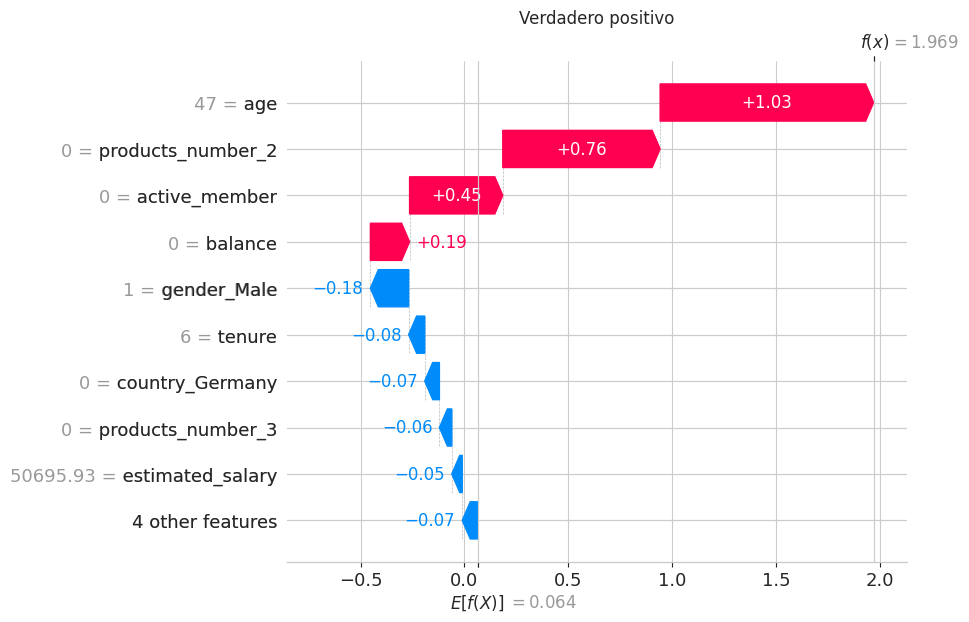

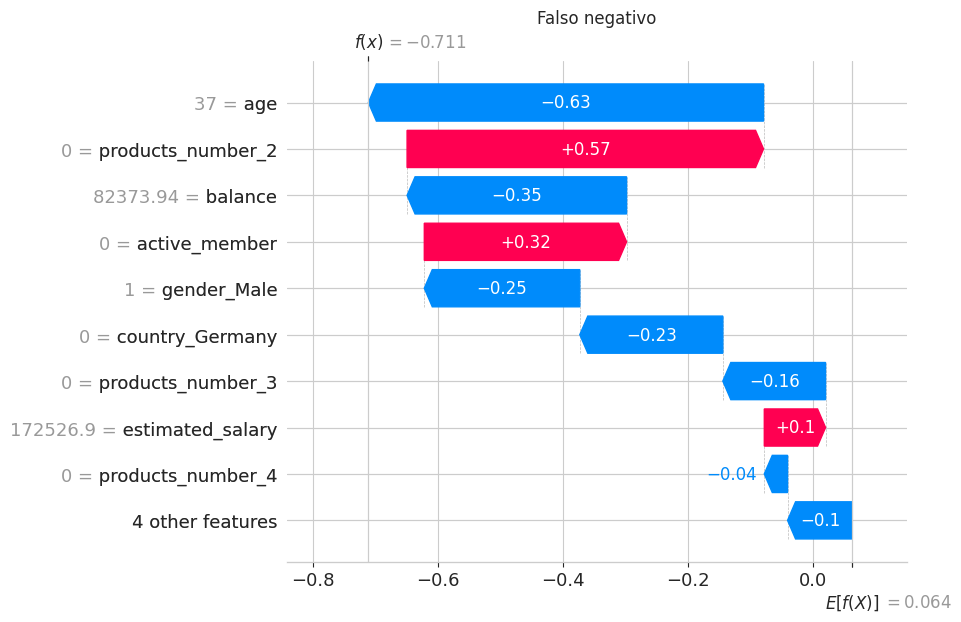

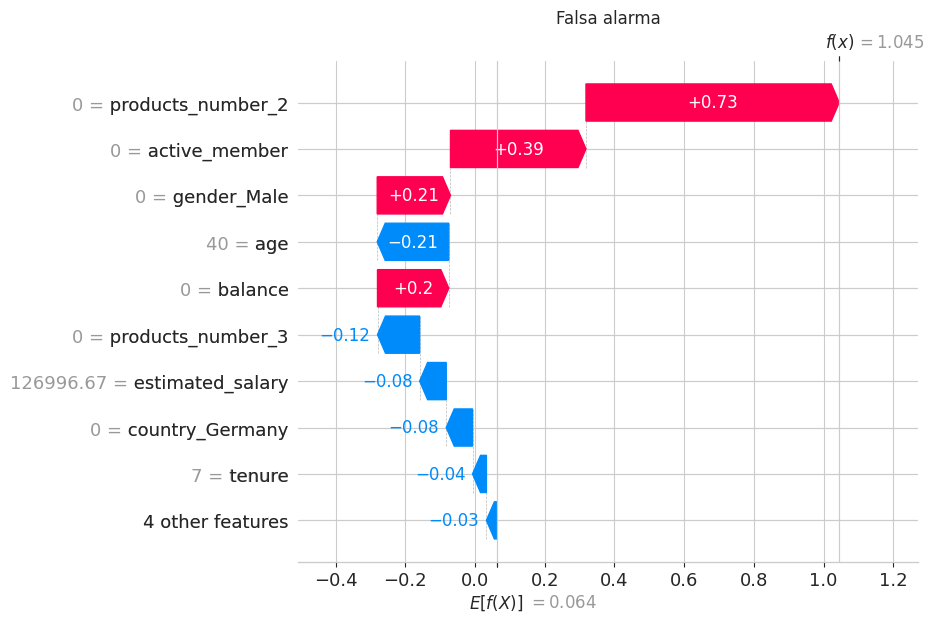

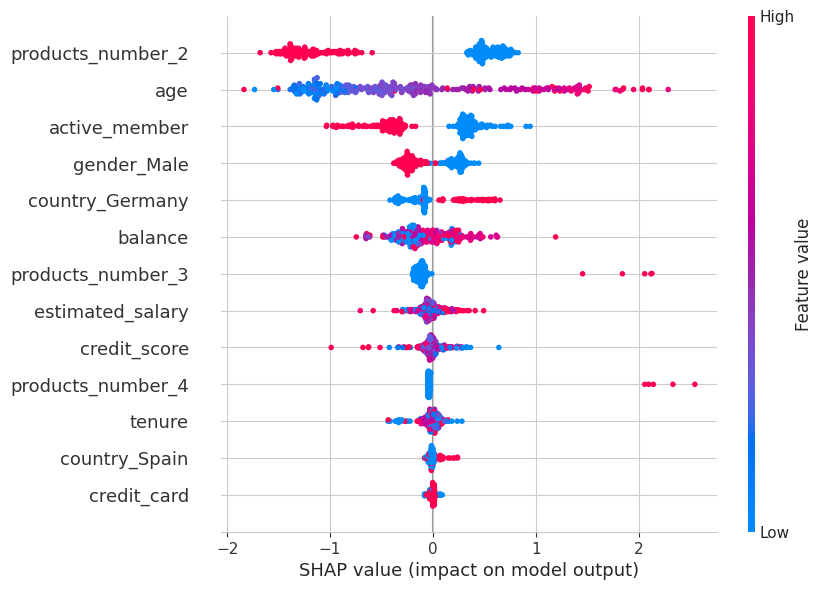

In [204]:
import shap

# El modelo elegido es de árboles, así que se usa TreeExplainer (recibe los datos escalados)
explicador_shap = shap.TreeExplainer(modelo_final)

def calcular_shap(X_esc, X_sin_escalar):
    """Calcula los valores SHAP y deja los datos originales para leer los gráficos."""
    v = explicador_shap(X_esc)
    if v.values.ndim == 3:  # Random Forest devuelve un valor por clase
        v = v[:, :, 1]
    v.data = X_sin_escalar.to_numpy()
    v.feature_names = list(X_sin_escalar.columns)
    return v

# SHAP de 300 clientes de prueba (global) y de los tres casos (individual)
X_muestra_shap = X_test_esc.sample(300, random_state=42)
valores = calcular_shap(X_muestra_shap, X_test.loc[X_muestra_shap.index])
indices = list(casos.values())
valores_casos = calcular_shap(X_test_esc.iloc[indices], X_test.iloc[indices])

# Aditividad: valor base + suma de valores SHAP = salida del modelo (log-odds en Gradient Boosting)
print('Valor base:', round(float(valores.base_values[0]), 3))
print(valores_casos.base_values[0] + valores_casos.values[0].sum(), modelo_final.decision_function(X_test_esc.iloc[[indices[0]]])[0])

# Gráficos de cascada de los tres casos
for k, nombre in enumerate(casos):
    shap.plots.waterfall(valores_casos[k], show=False)
    plt.title(nombre)
    plt.show()

# Importancia global: enjambre de 300 clientes
shap.plots.beeswarm(valores, max_display=13)

### Interpretación del punto 4: cómo funciona el modelo

Mirando el modelo en conjunto, lo primero que se ve es el efecto de la edad. En los ICE, la probabilidad promedio de abandono sube de cerca de 18% a los 25 años a cerca de 71% a los 55, y luego baja pasados los 65; esa bajada final se basa en muy pocos clientes mayores y no hay que tomarla como una regla. Con el número de productos pasa lo mismo que vi en el punto 1: con 2 productos el riesgo es el más bajo (24%), con uno sube a 52% y con 3 o 4 llega a 87-91%. El saldo casi no cambia la predicción hasta los 150.000 y da un salto en saldos altos (64% con 200.000), una zona con pocos clientes. Cuando separo la edad por actividad, los miembros inactivos tienen más riesgo a todas las edades y la brecha crece entre los 45 y los 65 años (a los 55, 87% frente a 51%); las curvas no son paralelas, así que la edad y la actividad se combinan. El enjambre de SHAP cuenta la misma historia: lo que más pesa es tener o no 2 productos y la edad, seguidos de ser miembro activo, el género, ser de Alemania y el saldo, mientras que el salario, el puntaje de crédito, la antigüedad y la tarjeta de crédito casi no mueven la predicción.

Pasando a los clientes individuales, los tres casos que expliqué son inactivos y tienen un solo producto:

| Caso | Perfil | Probabilidad del modelo | Qué empuja la predicción (LIME y SHAP) |
|---|---|---|---|
| Verdadero positivo | Hombre de 47 años, saldo 0 | 0,88 | La edad pesa muchísimo a favor de que se vaya, y también no tener 2 productos y estar inactivo. El R² local de LIME es 0,66, así que la explicación es confiable. |
| Falso negativo | Hombre de 37 años, saldo de unos 82.000 | 0,33 | Ser joven y tener saldo bajan el riesgo (en SHAP, la edad resta 0,63 y el saldo 0,35) y compensan lo que suman tener un solo producto y estar inactivo. |
| Falsa alarma | Mujer de 40 años, saldo 0 | 0,74 | Tener un solo producto, estar inactiva y ser mujer suben el riesgo; la edad lo baja un poco. |

Los dos errores se dieron con perfiles muy parecidos entre sí (inactivos, un solo producto, 37 y 40 años), que están justo en la frontera entre irse y quedarse: con las variables que tengo no hay cómo distinguirlos bien. Además, el R² local de LIME fue bajo en esos dos casos (0,24 y 0,22), así que sus pesos hay que tomarlos como orientativos. La prueba de estabilidad lo confirma a medias: con 1.000 simulaciones la edad y la inactividad aparecen siempre con casi el mismo peso, pero la tercera variable cambia según la semilla; con 5.000 simulaciones las tres variables y sus pesos quedan prácticamente iguales. SHAP, en cambio, cumple la suma de forma exacta: el valor base más los valores SHAP da 1,969, igual que la salida del modelo.

Algo que llama la atención es el valor base de SHAP: es 0,064 en log-odds, es decir, una probabilidad de cerca de 0,52 y no del 20% de clientes que se van. Se debe a que entrené con pesos que equilibran las dos clases, así que para el modelo los que se van y los que se quedan "pesan" lo mismo.

Comparo las tres técnicas en esta tabla:

| Técnica | Qué mira | Qué pregunta responde | Qué tan pesada es | Qué tan estable es | Limitaciones |
|---|---|---|---|---|---|
| ICE | Muchos clientes, una variable a la vez | ¿Cómo cambia la predicción si muevo esta variable? | Liviana | Estable, no usa azar | Puede crear clientes irreales si las variables están relacionadas, y muestra el modelo, no la realidad |
| LIME | Un cliente | ¿Qué variables explican la predicción de este cliente? | Media, simula 5.000 clientes por explicación | Depende del azar y de qué tan bueno sea el R² local | Cambia si cambia la forma de simular y puede ser poco fiable cuando el R² es bajo |
| SHAP | Un cliente y todo el conjunto | ¿Cuánto aporta cada variable a esta predicción y en general? | Liviana con modelos de árboles | Estable y suma exacto | Se lee en log-odds y es más lenta con otros modelos |

Para explicarle a un asesor por qué debe llamar a un cliente concreto sirve SHAP con su cascada, apoyado en LIME. Para explicarle a la gerencia cómo funciona el modelo en general sirven el enjambre de SHAP y los ICE. En los dos casos hay que dejar claro lo que ninguna técnica demuestra, que es la causalidad: solo explican cómo el modelo usa los datos, no por qué se van los clientes. Que los inactivos se vayan más no significa que activarlos evite que se vayan. También hay una cautela: el modelo usa el género como variable, y si se utiliza para decidir a quién ofrecer beneficios puede resultar discriminatorio, así que habría que revisarlo con el banco antes de ponerlo en producción.

En resumen, el modelo marca como clientes en riesgo a los de 45 a 65 años, inactivos, con un solo producto (o con 3 o 4) y, en menor medida, a los de Alemania, a las mujeres y a los de saldo alto. Los jóvenes y los que tienen 2 productos aparecen como los más estables.

## PUNTO 5. Generación de valor

Aquí quiero saber cuánta plata dejaría el modelo en un banco como el del enunciado y cuándo se recupera la inversión. Hago una estimación paramétrica en pesos colombianos: cada supuesto es una variable del código con su fuente al lado, de modo que se puede cambiar y recalcular todo.

### Etapa 1. Supuestos

Del enunciado tomo 20.000 clientes, una tasa de abandono anual de 15%, una oferta que convence al 30% de los que se iban a ir y un ingreso anual por cliente activo entre 500.000 y 900.000 pesos. Esos dos extremos y su punto medio son los tres escenarios del cálculo: bajo, medio y alto.

El resto son supuestos míos, con la fuente en la que me apoyo (la tabla está al final del punto). Para el costo por contacto no encontré una tarifa publicada de campañas de retención bancaria en Colombia, así que lo estimo repartiendo lo que cuesta un agente de telemercadeo (supongo 2.000.000 de pesos al mes) entre los contactos que alcanza a hacer, y le sumo el costo de la oferta (por ejemplo, exención de cuotas), que se paga por cada cliente contactado, como dice el enunciado. La inversión inicial incluye el equipo (un científico de datos y medio ingeniero de datos durante tres meses), la integración con el CRM y un 10% de imprevistos, como en el ejemplo de la guía. El costo mensual es el tiempo de un científico de datos dedicado a mantener el modelo. No cuento costos de infraestructura, porque supongo que el banco ya cuenta con ella.

In [205]:
# Supuestos del enunciado
clientes = 20_000                                                     # base de clientes del banco
tasa_churn = 0.15                                                     # abandono anual promedio del sector
r = 0.30                                                              # proporción de los que iban a abandonar que acepta la oferta
V_escenarios = {'Bajo': 500_000, 'Medio': 700_000, 'Alto': 900_000}   # ingreso anual por cliente activo (COP)

# Costo por contacto (COP) = costo de contactar + costo de la oferta (se paga por todos los contactados)
salario_agente = 2_000_000      # sueldo mensual de un agente de telemercadeo (supuesto; el promedio en Computrabajo es 1.678.965)
factor_carga = 1.5              # prestaciones y cargas sobre el salario (supuesto)
horas_mes, contactos_por_hora = 160, 6                                # (supuestos)
c_contacto = salario_agente * factor_carga / (horas_mes * contactos_por_hora)
c_oferta = 50_000               # beneficio ofrecido (p. ej. exención de cuotas), ~7% del ingreso medio (supuesto)
c = c_contacto + c_oferta

# Inversión inicial (COP): equipo del proyecto, integración y 10% de imprevistos
sal_cientifico = 6_000_000      # científico de datos intermedio (KeepCoding: 5,0 a 6,8 millones)
sal_ingeniero = 7_000_000       # ingeniero de datos (similar o superior al científico, según Coderhouse)
meses_proyecto = 3
personal = (1.0 * sal_cientifico + 0.5 * sal_ingeniero) * meses_proyecto * factor_carga
integracion = 10_000_000        # integración con el CRM del banco (supuesto)
inversion = (personal + integracion) * 1.10

# Costo mensual de operación (COP): mantenimiento del modelo con el 20% de un científico de datos
costo_mensual = 0.2 * sal_cientifico * factor_carga

print(f'Costo por contacto: {c_contacto:,.0f} (contacto) + {c_oferta:,.0f} (oferta) = {c:,.0f} COP')
print(f'Inversión inicial: {inversion:,.0f} COP')
print(f'Costo mensual de operación: {costo_mensual:,.0f} COP')

Costo por contacto: 3,125 (contacto) + 50,000 (oferta) = 53,125 COP
Inversión inicial: 58,025,000 COP
Costo mensual de operación: 1,800,000 COP


### Etapa 2. Ganancia esperada con el modelo

Convierto la matriz de confusión en plata con la matriz de costo-beneficio de la guía. Si contacto a un cliente que se iba a ir, con probabilidad r acepta la oferta y conservo su valor V, pero igual pago el costo del contacto c, así que la ganancia es r·V − c. Si contacto a uno que no se iba a ir, pierdo c. Y cuando el modelo deja escapar a un cliente, o no contacta a uno que se queda, no gano ni pierdo nada.

Hay un detalle importante: el modelo se evaluó con datos donde se va el 20% de los clientes, pero el banco tiene 15%. Por eso no reutilizo los conteos de la matriz, sino sus tasas (qué proporción de los que se van detecta y qué proporción de los que se quedan contacta por error), y las aplico a los 20.000 clientes del banco. Comparo el resultado con la opción sin modelo de contactar a todos.

In [206]:
# Tasas del modelo en prueba (umbral 0,5): se aplican a la base del banco, que tiene otra tasa de abandono
vn, fp, fn, vp = confusion_matrix(y_test, y_pred_test).ravel()
tpr = vp / (vp + fn)     # proporción de los que abandonan que el modelo detecta
fpr = fp / (fp + vn)     # proporción de los que se quedan que se contacta por error

def ganancia_anual(tpr, fpr, V, c=c, r=r):
    """Matriz de costo-beneficio: VP = r*V - c, FP = -c, FN = VN = 0."""
    abandonan = clientes * tasa_churn
    se_quedan = clientes - abandonan
    return tpr * abandonan * (r * V - c) - fpr * se_quedan * c

# Contactos y precisión que tendría el modelo en este banco
vp_banco = tpr * clientes * tasa_churn
fp_banco = fpr * clientes * (1 - tasa_churn)
print(f'Clientes que abandonan al año: {clientes * tasa_churn:,.0f}')
print(f'Contactados: {vp_banco + fp_banco:,.0f} (acertados: {vp_banco:,.0f}, falsas alarmas: {fp_banco:,.0f})')
print(f'Precisión en este banco: {vp_banco / (vp_banco + fp_banco):.2f} (en el conjunto de prueba fue {vp / (vp + fp):.2f})')

# Ganancia anual por escenario, frente a contactar a todos los clientes
filas = []
for nombre, V in V_escenarios.items():
    con_modelo = ganancia_anual(tpr, fpr, V)
    filas.append({'Escenario': nombre, 'Valor del cliente (COP)': V,
                  'Valor esperado por cliente': con_modelo / clientes,
                  'Ganancia anual con el modelo': con_modelo,
                  'Ganancia anual contactando a todos': ganancia_anual(1, 1, V),
                  'Beneficio mensual neto con el modelo': con_modelo / 12 - costo_mensual})
tabla_valor = pd.DataFrame(filas).set_index('Escenario')
with pd.option_context('display.float_format', '{:,.0f}'.format):
    display(tabla_valor)

Clientes que abandonan al año: 3,000
Contactados: 5,153 (acertados: 2,197, falsas alarmas: 2,956)
Precisión en este banco: 0.43 (en el conjunto de prueba fue 0.52)


,Valor del cliente (COP),Valor esperado por cliente,Ganancia anual con el modelo,Ganancia anual contactando a todos,Beneficio mensual neto con el modelo
Escenario,,,,,
Bajo,500000,"2,788","55,751,201","-612,500,000","2,845,933"
Medio,700000,"9,377","187,544,813","-432,500,000","13,828,734"
Alto,900000,"15,967","319,338,425","-252,500,000","24,811,535"


### Etapa 3. Punto de equilibrio

Para saber cuándo la inversión empieza a dejar dividendos calculo el beneficio mensual neto, que es la ganancia anual dividida entre 12 menos el costo mensual de operación. Con él saco los meses que tarda en recuperarse la inversión (inversión dividida entre beneficio mensual neto) y el ROI a 12 meses. También calculo la precisión de equilibrio, que es el costo por contacto dividido entre la tasa de éxito por el valor del cliente: si el modelo acierta menos que eso, cada contacto pierde plata en promedio. Y por último, el tamaño mínimo de banco con el que la ganancia de 12 meses cubre la inversión y la operación.

,Precisión de equilibrio,Beneficio mensual neto,Meses para recuperar la inversión,ROI a 12 meses,Clientes mínimos de la base (12 meses)
Escenario,,,,,
Bajo,0.35,"2,845,933.41",20.39,-0.41,"28,564.41"
Medio,0.25,"13,828,734.39",4.20,1.86,"8,491.30"
Alto,0.20,"24,811,535.38",2.34,4.13,"4,986.87"


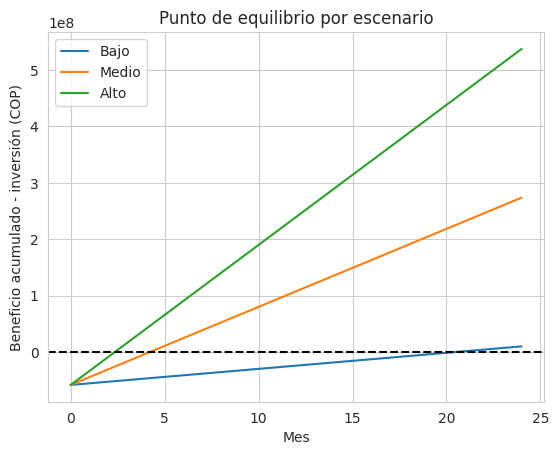

In [207]:
filas = []
for nombre, V in V_escenarios.items():
    bruta = ganancia_anual(tpr, fpr, V)
    B = bruta / 12 - costo_mensual                      # beneficio mensual neto de costos de operación
    meses = inversion / B if B > 0 else np.inf          # punto de equilibrio: t* = inversión / beneficio mensual
    g_cliente = bruta / clientes                        # ganancia bruta anual por cada cliente de la base
    filas.append({
        'Escenario': nombre,
        'Precisión de equilibrio': c / (r * V),
        'Beneficio mensual neto': B,
        'Meses para recuperar la inversión': meses,
        'ROI a 12 meses': (12 * B - inversion) / inversion,
        'Clientes mínimos de la base (12 meses)': (inversion + 12 * costo_mensual) / g_cliente,
    })
tabla_equilibrio = pd.DataFrame(filas).set_index('Escenario')
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(tabla_equilibrio)

# Beneficio acumulado menos la inversión, mes a mes
meses_eje = np.arange(0, 25)
for nombre in tabla_equilibrio.index:
    B = tabla_equilibrio.loc[nombre, 'Beneficio mensual neto']
    plt.plot(meses_eje, B * meses_eje - inversion, label=nombre)
plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Mes')
plt.ylabel('Beneficio acumulado - inversión (COP)')
plt.title('Punto de equilibrio por escenario')
plt.legend()
plt.show()

Además calculo el recall mínimo que debería tener el modelo para recuperar la inversión en 3, 6 o 12 meses, con la fórmula de la guía. Esa fórmula no incluye el costo mensual de operación, por eso sale un poco más optimista que la tabla anterior. Un valor mayor que 1 significa que, con esa precisión, no hay forma de recuperar la inversión en ese plazo.

In [208]:
# Recall mínimo para recuperar la inversión en k meses: R_min = I / (k * M * (r*V - c/P))
M = clientes * tasa_churn / 12                 # clientes que abandonan por mes
P = vp_banco / (vp_banco + fp_banco)           # precisión del modelo en este banco

filas = []
for nombre, V in V_escenarios.items():
    fila = {'Escenario': nombre}
    for k in [3, 6, 12]:
        denominador = k * M * (r * V - c / P)
        fila[f'{k} meses'] = inversion / denominador if denominador > 0 else np.inf
    filas.append(fila)
display(pd.DataFrame(filas).set_index('Escenario').round(2))
print(f'Recall del modelo: {tpr:.2f}')

,3 meses,6 meses,12 meses
Escenario,,,
Bajo,3.05,1.52,0.76
Medio,0.91,0.45,0.23
Alto,0.53,0.27,0.13


Recall del modelo: 0.73


### Etapa 4. Elección del umbral de decisión

Hasta ahora contacté a todo cliente con probabilidad de abandono de 0,5 o más, pero ese corte no tiene por qué ser el más rentable. Si lo bajo contacto a más clientes (detecto más de los que se van, pero también hay más falsas alarmas) y si lo subo pasa lo contrario. Pruebo varios umbrales en validación, escojo el que más ganancia da y solo entonces lo mido en prueba, para no elegir el corte mirando los datos de prueba. Además de los umbrales que sugiere la guía (de 0,3 a 0,7) pruebo 0,2, 0,8 y 0,9 para ver dónde está el máximo.

In [209]:
def tasas(y, prob, umbral):
    """Recall (TPR) y tasa de falsas alarmas (FPR) para un umbral dado."""
    pred = prob >= umbral
    return (pred & (y == 1)).sum() / (y == 1).sum(), (pred & (y == 0)).sum() / (y == 0).sum()

# El umbral se elige con validación y maximizando la ganancia del escenario medio
y_prob_val = modelo_final.predict_proba(X_val_esc)[:, 1]
V = V_escenarios['Medio']

filas = []
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    tpr_u, fpr_u = tasas(y_val.to_numpy(), y_prob_val, umbral)
    filas.append({'Umbral': umbral, 'Recall': tpr_u, 'Falsas alarmas (FPR)': fpr_u,
                  'Ganancia anual (COP)': ganancia_anual(tpr_u, fpr_u, V)})
tabla_umbral = pd.DataFrame(filas).set_index('Umbral')
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(tabla_umbral)

umbral_opt = tabla_umbral['Ganancia anual (COP)'].idxmax()
print('Umbral que maximiza la ganancia en validación:', umbral_opt)

# Resultado en prueba con el umbral elegido, frente al umbral 0,5
for u in [0.5, umbral_opt]:
    tpr_u, fpr_u = tasas(y_test.to_numpy(), y_prob_test, u)
    print(f'Umbral {u}: ganancia anual en prueba = {ganancia_anual(tpr_u, fpr_u, V):,.0f} COP')

,Recall,Falsas alarmas (FPR),Ganancia anual (COP)
Umbral,,,
0.200,0.882,0.485,"-23,118,249.220"
0.300,0.818,0.347,"72,109,548.879"
0.400,0.759,0.252,"129,397,724.959"
0.500,0.708,0.180,"170,879,143.782"
0.600,0.617,0.122,"179,685,997.631"
0.700,0.518,0.068,"182,756,137.301"
0.800,0.425,0.034,"169,430,126.390"
0.900,0.292,0.008,"130,232,752.012"


Umbral que maximiza la ganancia en validación: 0.7
Umbral 0.5: ganancia anual en prueba = 187,544,813 COP
Umbral 0.7: ganancia anual en prueba = 201,734,460 COP


### Etapa 5. Sensibilidad

El costo por contacto (sobre todo el de la oferta) y la tasa de éxito de la oferta son los supuestos más inciertos. Recalculo la ganancia anual del escenario medio con distintos valores de ambos para ver cuánto cambia la conclusión.

In [210]:
# Sensibilidad de la ganancia anual (escenario medio) al costo por contacto y a la tasa de éxito de la oferta
V = V_escenarios['Medio']
costos = [c_contacto, c_contacto + 25_000, c_contacto + 50_000, c_contacto + 100_000]
exitos = [0.20, 0.30, 0.40]

sensibilidad = pd.DataFrame(
    {f'éxito = {e:.0%}': [ganancia_anual(tpr, fpr, V, c=cc, r=e) for cc in costos] for e in exitos},
    index=[f'costo por contacto = {cc:,.0f}' for cc in costos],
)
with pd.option_context('display.float_format', '{:,.0f}'.format):
    display(sensibilidad)

,éxito = 20%,éxito = 30%,éxito = 40%
"costo por contacto = 3,125","291,416,496","445,175,710","598,934,924"
"costo por contacto = 28,125","162,601,048","316,360,261","470,119,475"
"costo por contacto = 53,125","33,785,599","187,544,813","341,304,026"
"costo por contacto = 103,125","-223,845,298","-70,086,085","83,673,129"


### Resultados del punto 5

Para un banco de 20.000 clientes, donde se van 3.000 al año, y con el modelo usando el umbral de 0,5, la ganancia es la siguiente (en pesos; la inversión inicial estimada es de 58 millones y operar cuesta 1,8 millones al mes):

| Escenario (ingreso por cliente) | Ganancia anual con el modelo | Contactando a todos | Beneficio mensual neto | Recuperación de la inversión | ROI a 12 meses |
|---|---|---|---|---|---|
| Bajo (500.000) | 56 millones | -613 millones | 2,8 millones | 20 meses | -41% |
| Medio (700.000) | 188 millones | -433 millones | 13,8 millones | 4,2 meses | +186% |
| Alto (900.000) | 319 millones | -253 millones | 24,8 millones | 2,3 meses | +413% |

Lo primero que se nota es que el modelo gana plata justo donde contactar a todos la pierde. Con una oferta que cuesta cerca de 53.100 por contacto, llamar a los 20.000 clientes da pérdidas en los tres escenarios. El modelo contacta a unos 5.150, de los cuales acierta con unos 2.200 y se equivoca con unos 2.950. Su precisión en este banco baja de 52% a 43%, porque aquí se va el 15% de los clientes y no el 20%, pero igual queda por encima de la precisión de equilibrio (entre 20% y 35% según el escenario), que es el mínimo para que un contacto no pierda plata.

Sobre el punto de equilibrio, en los escenarios medio y alto la inversión se recupera en unos 4 y 2 meses. En el escenario bajo tarda 20 meses, así que el primer año no se recupera. Con la fórmula de la guía, el recall mínimo para recuperar la inversión en 3 meses es 0,91 en el escenario medio (el modelo tiene 0,73, así que no alcanza) y 0,53 en el alto (sí alcanza); para recuperarla en 6 meses basta con 0,45 en el medio. Un banco necesitaría al menos 8.500 clientes en el escenario medio, o 5.000 en el alto, para recuperarla en un año; con ingresos bajos necesitaría unos 28.600.

Subir el umbral de 0,5 a 0,7, que fue el mejor en validación, mejora la ganancia en prueba de 188 a 202 millones (un 8%) a costa de detectar menos clientes; entre 0,5 y 0,7 la ganancia es casi plana. En la sensibilidad se ve que todo depende mucho del costo de la oferta: con 100.000 por contacto y 30% de éxito, el escenario medio pierde 70 millones, y con 40% de éxito gana 84 millones. Y si el costo por contacto fuera solo el de una llamada (unos 3.100 pesos), contactar a todos daría más ganancia que usar el modelo, porque equivocarse casi no costaría.

Hay varias limitaciones que conviene tener presentes. El modelo se entrenó con clientes de Francia, Alemania y España, y no sé si sus tasas de detección y de falsas alarmas se mantendrían en un banco colombiano; el cálculo supone que sí. Usé el ingreso como valor del cliente retenido durante un año, como pide el enunciado, pero el ingreso no es utilidad: si el valor real fuera el margen (por ejemplo, 30% del ingreso) y la oferta costara lo mismo, la ganancia sería negativa en los tres escenarios (entre -175 y -96 millones), aunque por otro lado un cliente retenido puede quedarse más de un año, lo que mejoraría el resultado. Varios supuestos son míos y no tienen una fuente directa: el salario del agente (2.000.000), el costo de la oferta (50.000), la carga de prestaciones (1,5), los contactos por hora (6) y el costo de integración (10 millones). El 30% de éxito de la oferta viene del enunciado y no se ha probado, así que habría que validarlo con una campaña piloto con grupo de control. Además, el modelo es moderado: deja escapar a 27 de cada 100 clientes que se van y, en este banco, unas 57 de cada 100 alertas serían falsas. No incluí costos de infraestructura, reentrenamiento, monitoreo ni de cumplimiento regulatorio, ni que usar el género como variable puede obligar a quitarlo del modelo. Tampoco segmenté por país, como hace la guía en su ejercicio, porque el enunciado habla de un banco con características promedio.

### Declaración de IA Generaiva

- Para este taller se utilizó la IA generativa para algunas tareas con el fin de aumentar la calidad del trabajo, por ejemplo para la redacción de los markdown se utilzó ya qué de mi parte explicaba los coceptos, las funcionalidades, y los analisis pero le Pedí a claude ayuda para la corrección de estilo, que lo redactara mas profesional, le diera orden y si encontraba errores hiciera las correcciones respectivas.

- Para los gráficos traté de implementarlos del las prácticas pero si detectaba algún error en la sintaxis o en la visualización, con claude code hice el debug y mejoramiento de las mismas.

- Para el punto 5 claude fué el generador de los supuestos, por practicidad coherencia en la data.

- Para las diapositivas utilicé una plantilla de canva, la creé pero luego con claude design le di instrucciones para que la ajutara y me entragara una diapositiva mas profesional.